# Section 1 · Perform quantum operations

Exam weight: 16% of C1000-179 · about 11 of the 68 questions

## Study path

**Core first pass:** Pauli labels, matrices and products; standard gates and probabilities; circuit composition and the distinction between global and relative phase.

- Core coding practice: **1.1–1.4 and 1.6**.
- Optional second pass: **1.5 (exact phase correction) and 1.7 (manual feature-map construction); the fidelity example and the individually marked API questions.**
- Core review: answer all questions without an optional label.

Run the setup cell, then work through the unmarked examples in order. Complete a practice starter before running its check cell. At an optional block, use its **continue with the core path** link to skip the entire block; the remaining core cells do not depend on it. Notebook tags `study-core` and `study-optional` also identify the two paths; ordinary **Run All** does not filter tags.

Core/optional labels set a learning priority, not a boundary on what the exam may ask. The [official objectives and sample](https://www.ibm.com/training/certification/ibm-certified-quantum-computation-using-qiskit-v2x-developer-associate-C9008400) remain the coverage reference.

**Jump to:** [Pauli operators](#s1-core-2) · [Quantum operations](#s1-core-30) · [Review](#s1-core-82)

Official objectives
- 1.1 Define Pauli operators
- 1.2 Apply quantum operations

Topics
- build `Pauli`, `PauliList` and `SparsePauliOp` objects from labels, `(z, x)` arrays, sparse lists and circuits, and read Qiskit's little-endian labels, phases and matrices correctly;
- multiply and combine operators with `compose`, `dot`, `tensor` and `expand` without mixing up the order, and decide whether two Paulis commute;
- write down the standard single- and multi-qubit gates, separate global from relative phase, and tell Clifford from non-Clifford gates;
- evolve a `Statevector` or `Operator` through a circuit and compute measurement probabilities, for example after `RY(θ)`;
- manipulate circuits with `compose`, `tensor`, `inverse`, `power`, `repeat`, `to_gate`, `control` and `decompose`, and read `depth`, `size`, `width` and `count_ops`;
- build data-encoding feature maps with `z_feature_map`, `zz_feature_map` and `pauli_feature_map`.

Built from the Qiskit Advocate KR study notebooks `1_Pauli_Operators`, `2_1_Standard_Gates`, `2_2_Advanced_Circuits_ko`, `2_3_Quantum_Operations_FeatureMaps`, `2_4_Circuit_Mechanics` and `Review/W6T01_Qs`, and the QAMP 2025 tutorial (links in the Sources cell at the end).

Everything runs locally with `qiskit.quantum_info` and a preset pass manager; no account or backend is needed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import qiskit
import qiskit_ibm_runtime
from qiskit import QuantumCircuit
from qiskit.exceptions import QiskitError
from qiskit.circuit.library import (
    XGate, YGate, ZGate, HGate, SGate, SdgGate, TGate, SXGate, PhaseGate,
    RXGate, RYGate, RZGate, UGate, CXGate, CYGate, CZGate, SwapGate, CCXGate,
    MCXGate, QFTGate, get_standard_gate_name_mapping,
    z_feature_map, zz_feature_map, pauli_feature_map,
)
from qiskit.quantum_info import (
    Pauli, PauliList, SparsePauliOp, Operator, Statevector, Clifford,
    process_fidelity, average_gate_fidelity,
)
from qiskit.transpiler import generate_preset_pass_manager

# NumPy 2 prints scalars as np.float64(...) and np.str_(...); legacy mode keeps outputs readable.
np.set_printoptions(legacy="1.25", precision=4, suppress=True)

print("qiskit", qiskit.__version__, "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__, "| numpy", np.__version__)

qiskit 2.0.3 | qiskit-ibm-runtime 0.40.1 | numpy 2.4.6


<a id="s1-core-2"></a>

## 1.1 Define Pauli operators

### Single-qubit Paulis

| Operator | Matrix | Action on the Bloch sphere | Eigenvalues |
|---|---|---|---|
| $I$ | $\begin{pmatrix}1&0\\0&1\end{pmatrix}$ | nothing | $+1, +1$ |
| $X$ | $\begin{pmatrix}0&1\\1&0\end{pmatrix}$ | bit flip, $\pi$ about $x$ | $\pm 1$ ($\lvert\pm\rangle$) |
| $Y$ | $\begin{pmatrix}0&-i\\i&0\end{pmatrix}$ | bit and phase flip, $\pi$ about $y$ | $\pm 1$ |
| $Z$ | $\begin{pmatrix}1&0\\0&-1\end{pmatrix}$ | phase flip, $\pi$ about $z$ | $\pm 1$ ($\lvert 0\rangle, \lvert 1\rangle$) |

Algebra you should be able to use without a computer:
- $X^2 = Y^2 = Z^2 = I$; every Pauli is Hermitian and unitary.
- $XY = iZ$, $YZ = iX$, $ZX = iY$ (cyclic), and reversing the order flips the sign: $YX = -iZ$. So two different non-identity Paulis anticommute.
- $Y = iXZ$. This is why Qiskit can describe every Pauli with two bits, $z$ and $x$, plus a phase.

An $n$-qubit Pauli is a tensor product such as $X \otimes I \otimes Z$ times a phase from $\{+1, -i, -1, +i\}$.

In [2]:
I2, X, Y, Z = (Pauli(c).to_matrix() for c in "IXYZ")

print("X @ Y == iZ :", np.allclose(X @ Y, 1j * Z))
print("Y @ Z == iX :", np.allclose(Y @ Z, 1j * X))
print("Z @ X == iY :", np.allclose(Z @ X, 1j * Y))
print("XY == -YX   :", np.allclose(X @ Y, -(Y @ X)))
print("Y == iXZ    :", np.allclose(Y, 1j * X @ Z))

X @ Y == iZ : True
Y @ Z == iX : True
Z @ X == iY : True
XY == -YX   : True
Y == iXZ    : True


### Creating a `Pauli`

`qiskit.quantum_info.Pauli` has three common constructors:

| Input | Example | Notes |
|---|---|---|
| label string | `Pauli("-iXZ")` | letters `I X Y Z`, optional phase prefix `""`, `"-"`, `"i"`, `"-i"` (also `"+"`, `"j"`) |
| `(z, x)` Boolean arrays | `Pauli((z, x))` | element `k` of each array describes qubit `k` |
| circuit of Pauli gates | `Pauli(qc)` | only `I`, `X`, `Y`, `Z` (or `PauliGate`) instructions are allowed |

Little-endian labels. The rightmost character of a label acts on qubit 0. `Pauli("XYZ")` means $Z$ on qubit 0, $Y$ on qubit 1 and $X$ on qubit 2. Indexing `p[k]` returns the single-qubit Pauli on qubit `k`.

In the `(z, x)` form each qubit gets one bit pair. Qiskit absorbs the $-i$ in $Y = -iZX$, so `(True, True)` gives a plain `Y` with phase $+1$:

| `(z[k], x[k])` | `(False, False)` | `(False, True)` | `(True, False)` | `(True, True)` |
|---|---|---|---|---|
| Pauli on qubit `k` | $I$ | $X$ | $Z$ | $Y$ |

The `phase` attribute. `Pauli` stores a phase exponent $q \in \{0, 1, 2, 3\}$, and the coefficient is $(-i)^{q}$:

| label prefix | `""` | `"-i"` | `"-"` | `"i"` |
|---|---|---|---|---|
| coefficient | $+1$ | $-i$ | $-1$ | $+i$ |
| `p.phase` | 0 | 1 | 2 | 3 |

A `Pauli` can only carry these four phases. Multiplying by `2` raises an error, and `Pauli + Pauli` is not defined; weighted sums are what `SparsePauliOp` is for.

Read a Pauli label from right to left to go from qubit 0 upward. For `(z, x)` arrays it is the other way round: array element 0 is qubit 0, and it ends up as the last character of the printed label.

In [3]:
p = Pauli("XYZ")
print("label:", p.to_label(), "| num_qubits:", p.num_qubits)
for q in range(p.num_qubits):
    print(f"  qubit {q} -> {p[q]}")
print("x array:", p.x, "| z array:", p.z)   # x[k] (z[k]) is True where qubit k carries X or Y (Z or Y)

z = np.array([True, False, True, False])   # index k refers to qubit k
x = np.array([False, False, True, True])
print("Pauli((z, x)) =", Pauli((z, x)))     # qubit 0: Z, 1: I, 2: Y, 3: X -> printed right to left

pc = QuantumCircuit(3)
pc.z(0)
pc.x(1)
pc.y(2)
print("Pauli(circuit) =", Pauli(pc))
not_pauli = QuantumCircuit(1)
not_pauli.h(0)
try:
    Pauli(not_pauli)                        # Qiskit tries to unroll H and gives up
except QiskitError as err:
    print("Pauli(circuit with H) ->", type(err).__name__, err)

print()
coefficient = {0: "+1", 1: "-i", 2: "-1", 3: "+i"}
for label in ["XZ", "-iXZ", "-XZ", "iXZ"]:
    print(f"{label:>5}: phase = {Pauli(label).phase} -> coefficient {coefficient[Pauli(label).phase]}")
print("Pauli('-X') == Pauli('X')     :", Pauli("-X") == Pauli("X"))
print("Pauli('-X').equiv(Pauli('X')) :", Pauli("-X").equiv(Pauli("X")))
try:
    2 * Pauli("X")
except QiskitError as err:
    print("2 * Pauli('X') ->", err)
try:
    Pauli("X") + Pauli("Z")
except TypeError as err:
    print("Pauli + Pauli  -> TypeError:", err)

label: XYZ | num_qubits: 3
  qubit 0 -> Z
  qubit 1 -> Y
  qubit 2 -> X
x array: [False  True  True] | z array: [ True  True False]
Pauli((z, x)) = XYIZ
Pauli(circuit) = YXZ
Pauli(circuit with H) -> QiskitError 'Cannot apply Instruction: u'

   XZ: phase = 0 -> coefficient +1
 -iXZ: phase = 1 -> coefficient -i
  -XZ: phase = 2 -> coefficient -1
  iXZ: phase = 3 -> coefficient +i
Pauli('-X') == Pauli('X')     : False
Pauli('-X').equiv(Pauli('X')) : True
2 * Pauli('X') -> 'Pauli can only be multiplied by 1, -1j, -1, 1j.'
Pauli + Pauli  -> TypeError: unsupported operand type(s) for +: 'Pauli' and 'Pauli'


`phase` is not "the power of $i$". `Pauli("-iXY").phase` is `1` and `Pauli("iXY").phase` is `3`, because the coefficient is $(-i)^{\text{phase}}$. Also, `==` compares the phase while `.equiv()` ignores it.

### Matrix form and products: `compose` vs `dot`, `tensor` vs `expand`

`to_matrix()` builds the tensor product in the order the label is written: `Pauli("XZ").to_matrix()` is `np.kron(X, Z)` $= X \otimes Z$. The leftmost factor belongs to the highest qubit, so rows and columns are indexed by the bitstring $|q_{n-1}\dots q_1 q_0\rangle$. `Operator.from_label("XZ")` gives the same matrix.

All `quantum_info` operators (`Pauli`, `SparsePauliOp`, `Operator`, `Clifford`) share these product conventions:

| Call | Shortcut | Result | Read it as |
|---|---|---|---|
| `A.compose(B)` | `A & B` | $B \cdot A$ | apply A first, then B (circuit order) |
| `A.dot(B)` | `A @ B` | $A \cdot B$ | ordinary matrix product (B acts first) |
| `A.compose(B, front=True)` | | $A \cdot B$ | same as `dot` |
| `A.tensor(B)` | `A ^ B` | $A \otimes B$ | B on the low qubits |
| `A.expand(B)` | | $B \otimes A$ | A on the low qubits |

`compose` also accepts `qargs=[...]` to apply a smaller operator to selected qubits.

A typical item shows `Pauli("XZ")` (or a tensor product such as $X \otimes Z$) and asks for the matrix, or for which qubit carries which Pauli. Two facts settle it: label order equals Kronecker order ($X\otimes Z$), and the rightmost letter acts on qubit 0.

In [4]:
print(Pauli("XZ").to_matrix().real)
print("Pauli('XZ') == kron(X, Z):", np.allclose(Pauli("XZ").to_matrix(), np.kron(X, Z)))
print("Pauli('XZ') == kron(Z, X):", np.allclose(Pauli("XZ").to_matrix(), np.kron(Z, X)))
print("Operator.from_label('XZ') equals it:", Operator.from_label("XZ") == Operator(Pauli("XZ")))
print()
PX, PY, PZ = Pauli("X"), Pauli("Y"), Pauli("Z")
print("X.compose(Y) =", PX.compose(PY), "  (Y·X: X first, then Y)")
print("X.dot(Y)     =", PX.dot(PY), "   (X·Y: matrix product)")
print("X & Y =", PX & PY, "| X @ Y =", PX @ PY)
print("compose(front=True) == dot:", PX.compose(PY, front=True) == PX.dot(PY))
print("matrix check Y·X == -iZ   :", np.allclose(Y @ X, -1j * Z))
print()
print("X.tensor(Z) =", PX.tensor(PZ), " (X⊗Z: Z on qubit 0)")
print("X.expand(Z) =", PX.expand(PZ), " (Z⊗X: X on qubit 0)")
print("X ^ Z       =", PX ^ PZ)
print("XX.compose(Z, qargs=[1]) =", Pauli("XX").compose(PZ, qargs=[1]))

[[ 0.  0.  1.  0.]
 [ 0.  0.  0. -1.]
 [ 1.  0.  0.  0.]
 [ 0. -1.  0.  0.]]
Pauli('XZ') == kron(X, Z): True
Pauli('XZ') == kron(Z, X): False
Operator.from_label('XZ') equals it: True

X.compose(Y) = -iZ   (Y·X: X first, then Y)
X.dot(Y)     = iZ    (X·Y: matrix product)
X & Y = -iZ | X @ Y = iZ
compose(front=True) == dot: True
matrix check Y·X == -iZ   : True

X.tensor(Z) = XZ  (X⊗Z: Z on qubit 0)
X.expand(Z) = ZX  (Z⊗X: X on qubit 0)
X ^ Z       = XZ
XX.compose(Z, qargs=[1]) = iYX


`A.compose(B)` is not the matrix product $AB$. It follows circuit order ("do A, then B"), which is the matrix $BA$. For Paulis the two orders differ by a sign whenever the factors anticommute: `Pauli("X").compose(Pauli("Y"))` is `-iZ`, but `Pauli("X").dot(Pauli("Y"))` is `iZ`.

### Commutation and other `Pauli` methods

Two Pauli strings either commute or anticommute. Count the positions where both are non-identity and different. An even count means they commute; an odd count means they anticommute. Qiskit gives you `commutes()` and `anticommutes()`.

| Method | Effect | Example |
|---|---|---|
| `adjoint()` | conjugate transpose (flips an imaginary phase) | `Pauli("-iZX").adjoint()` → `iZX` |
| `conjugate()`, `transpose()` | complex conjugate / transpose | `Pauli("Y").conjugate()` → `-Y` |
| `delete(qubits)` | remove qubits (by qubit index, not string position) | `Pauli("XYZ").delete(0)` → `XY` |
| `insert(qubit, pauli)` | add qubits at an index | `Pauli("XZ").insert(1, Pauli("Y"))` → `XYZ` |
| `evolve(gate_or_clifford)` | conjugate the Pauli by a Clifford (Heisenberg picture by default) | `Pauli("IX").evolve(CXGate())` → `XX` |
| `to_instruction()` | a circuit instruction (`PauliGate`) | `qc.append(p.to_instruction(), ...)` |

In [5]:
pairs = [("XX", "ZZ"), ("XZ", "ZZ"), ("XY", "YX"), ("XI", "IZ"), ("XYZ", "ZZZ")]
for a, b in pairs:
    pa, pb = Pauli(a), Pauli(b)
    print(f"{a:>3} vs {b:<3}: commutes={pa.commutes(pb)!s:<5}  anticommutes={pa.anticommutes(pb)}")
print()
print("adjoint   :", Pauli("-iZX").adjoint())
print("conjugate :", Pauli("Y").conjugate())
print("delete(0) :", Pauli("XYZ").delete(0))
print("insert    :", Pauli("XZ").insert(1, Pauli("Y")))
print("evolve    :", Pauli("IX").evolve(CXGate()), "(X on the control of CX spreads to the target)")

 XX vs ZZ : commutes=True   anticommutes=False
 XZ vs ZZ : commutes=False  anticommutes=True
 XY vs YX : commutes=True   anticommutes=False
 XI vs IZ : commutes=True   anticommutes=False
XYZ vs ZZZ: commutes=True   anticommutes=False

adjoint   : iZX
conjugate : -Y
delete(0) : XY
insert    : XYZ
evolve    : XX (X on the control of CX spreads to the target)


### `PauliList` and `SparsePauliOp`

- `PauliList` is an array of Paulis (no coefficients). Indexing returns a `Pauli`; methods such as `commutes()` work element-wise.
- `SparsePauliOp` is a weighted sum of Paulis, $\sum_j c_j P_j$. It is the standard observable/Hamiltonian format and the usual way to pass observables to `EstimatorV2` (Section 6).

| Constructor | Example | Note |
|---|---|---|
| labels + coeffs | `SparsePauliOp(["ZZ", "XI"], coeffs=[1.0, -0.5])` | coeffs default to 1 |
| `from_list` | `SparsePauliOp.from_list([("ZZ", 1.0), ("XI", -0.5)])` | full-length labels |
| `from_sparse_list` | `SparsePauliOp.from_sparse_list([("ZZ", [0, 1], 1.0), ("X", [1], -0.5)], num_qubits=2)` | only non-identity factors plus their qubit indices |

Useful members: `paulis` (a `PauliList`), `coeffs`, `num_qubits`, `simplify()` (merges duplicate labels and drops zero terms), `to_matrix()` (dense, or `sparse=True`), and the arithmetic `+`, `-`, scalar `*`, `compose`, `dot`, `tensor`.

In `from_sparse_list`, the string is not read right to left. For `("XZ", [0, 2], c)` the first character `X` goes to qubit 0 and `Z` goes to qubit 2, so the full label is `"ZIX"`. In `from_list` and in plain labels, the rightmost character is qubit 0 as usual.

In [6]:
pl = PauliList(["XXI", "IZZ", "ZIZ"])
print(pl, "| len:", len(pl), "| pl[1] =", pl[1])
print("commute with XII:", pl.commutes(Pauli("XII")))

h1 = SparsePauliOp(["ZZ", "XI"], coeffs=[1.0, -0.5])
h2 = SparsePauliOp.from_list([("ZZ", 1.0), ("XI", -0.5)])
h3 = SparsePauliOp.from_sparse_list([("ZZ", [0, 1], 1.0), ("X", [1], -0.5)], num_qubits=2)
print("three constructors agree:", h1 == h2 == h3)
print(h3)

# from_sparse_list: the i-th character goes to the i-th listed qubit
op = SparsePauliOp.from_sparse_list([("XZ", [0, 2], 1.0)], num_qubits=3)
print("('XZ', [0, 2]) ->", op.paulis)

# arithmetic and simplify: (X + Z)(X + Z) = X² + XZ + ZX + Z² = 2I, because XZ = -ZX
A = SparsePauliOp("X") + SparsePauliOp("Z")
square = A.compose(A)
print(square)
print(square.simplify())

['XXI', 'IZZ', 'ZIZ'] | len: 3 | pl[1] = IZZ
commute with XII: [ True  True False]
three constructors agree: True
SparsePauliOp(['ZZ', 'XI'],
              coeffs=[ 1. +0.j, -0.5+0.j])
('XZ', [0, 2]) -> ['ZIX']
SparsePauliOp(['I', 'Y', 'Y', 'I'],
              coeffs=[1.+0.j, 0.+1.j, 0.-1.j, 1.+0.j])
SparsePauliOp(['I'],
              coeffs=[2.+0.j])


In [7]:
# A 3-qubit transverse-field Ising Hamiltonian  H = -J Σ Z_i Z_{i+1} - h Σ X_i
n, J, hx = 3, 1.0, 0.5
ising = SparsePauliOp.from_sparse_list(
    [("ZZ", [i, i + 1], -J) for i in range(n - 1)] + [("X", [i], -hx) for i in range(n)],
    num_qubits=n,
)
print(ising)
mat = ising.to_matrix()
print("shape:", mat.shape, "| Hermitian:", np.allclose(mat, mat.conj().T))
print("lowest eigenvalue:", round(float(np.linalg.eigvalsh(mat)[0]), 4))

SparsePauliOp(['IZZ', 'ZZI', 'IIX', 'IXI', 'XII'],
              coeffs=[-1. +0.j, -1. +0.j, -0.5+0.j, -0.5+0.j, -0.5+0.j])
shape: (8, 8) | Hermitian: True
lowest eigenvalue: -2.4032


### `Operator`: general matrices and the two kinds of equality

`Operator` wraps any matrix. You can build it from a gate, a measurement-free circuit, a `Pauli`/`SparsePauliOp`, a NumPy array, or a label (`Operator.from_label` accepts `I X Y Z H S T 0 1 + - r l`). Useful members: `data`, `dim`, `num_qubits`, `is_unitary()`, `adjoint()`, `power(n)`, and the same `compose` / `dot` / `tensor` / `expand` rules as above.

- `A == B` compares the matrices exactly, including the global phase.
- `A.equiv(B)` is `True` when they are equal up to a global phase.

In [8]:
bell_circ = QuantumCircuit(2, name="bell")
bell_circ.h(0)
bell_circ.cx(0, 1)
bell_op = Operator(bell_circ)
print("dim:", bell_op.dim, "| num_qubits:", bell_op.num_qubits, "| unitary:", bell_op.is_unitary())
print(bell_op.data.real.round(3))

p_op, rz_op, s_op = Operator(PhaseGate(np.pi / 2)), Operator(RZGate(np.pi / 2)), Operator(SGate())
print("P(pi/2) == S          :", p_op == s_op)
print("P(pi/2) == RZ(pi/2)   :", p_op == rz_op)
print("P(pi/2).equiv(RZ)     :", p_op.equiv(rz_op))
print("ratio P/RZ (entry 00) :", (p_op.data[0, 0] / rz_op.data[0, 0]).round(4), " = e^{i pi/4}, a global phase")

dim: (4, 4) | num_qubits: 2 | unitary: True
[[ 0.707  0.707  0.     0.   ]
 [ 0.     0.     0.707 -0.707]
 [ 0.     0.     0.707  0.707]
 [ 0.707 -0.707  0.     0.   ]]
P(pi/2) == S          : True
P(pi/2) == RZ(pi/2)   : False
P(pi/2).equiv(RZ)     : True
ratio P/RZ (entry 00) : (0.7071+0.7071j)  = e^{i pi/4}, a global phase


If an option says two circuits "implement the same operation", decide whether the question means exact equality (`==`, global phase included) or physical equivalence (`equiv`, global phase ignored). $P(\lambda)$ and $R_Z(\lambda)$ are the standard example: they are not `==`, but they are `equiv`.

### Practice 1.1 — Build a Hamiltonian with `from_sparse_list`

Create the 4-qubit operator

$$H = 0.5\, Z_0 Z_1 \;-\; 1.2\, X_2 \;+\; 0.3\, Y_1 Z_3$$

(subscripts are qubit indices) as `ex1_op`, using `SparsePauliOp.from_sparse_list`.

In [ ]:
ex1_op = None  # TODO: SparsePauliOp.from_sparse_list([...], num_qubits=4)

In [ ]:
# Run this cell to check your answer
ex1_expected = SparsePauliOp.from_list([("IIZZ", 0.5), ("IXII", -1.2), ("ZIYI", 0.3)])
assert isinstance(ex1_op, SparsePauliOp), "ex1_op must be a SparsePauliOp"
assert ex1_op.num_qubits == 4, "ex1_op must act on 4 qubits"
assert np.allclose(ex1_op.to_matrix(), ex1_expected.to_matrix()), "check qubit indices and coefficients"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex1_op = SparsePauliOp.from_sparse_list(
    [("ZZ", [0, 1], 0.5), ("X", [2], -1.2), ("YZ", [1, 3], 0.3)],
    num_qubits=4,
)
print(ex1_op)
```

In `from_sparse_list` each term is `(paulis, qubit_indices, coeff)` and character `i` of the string lands on `qubit_indices[i]`. So `("YZ", [1, 3], 0.3)` is $Y$ on qubit 1 and $Z$ on qubit 3, whose full little-endian label is `"ZIYI"`.

</details>

### Practice 1.2 — Order of Pauli products

A circuit applies the 2-qubit Pauli $P_1$ = `ex2_p1 = Pauli("XY")` and then $P_2$ = `ex2_p2 = Pauli("ZX")`.

1. Store the single `Pauli` (including its phase) that equals the whole sequence in `ex2_total`. Use `compose` or `dot`, and work out on paper which one matches the circuit order.
2. Set `ex2_commute` to `True` or `False` depending on whether $P_1$ and $P_2$ commute. Decide by counting positions first, then confirm with a method call.

In [ ]:
ex2_p1, ex2_p2 = Pauli("XY"), Pauli("ZX")
ex2_total = None     # TODO
ex2_commute = None   # TODO: True or False

In [ ]:
# Run this cell to check your answer
assert isinstance(ex2_total, Pauli), "ex2_total must be a Pauli"
assert ex2_total == Pauli("ZX").dot(Pauli("XY")), "the overall operator is P2 · P1"
assert ex2_total == Pauli("-YZ")
assert ex2_commute is not None and bool(ex2_commute) is True, "XY and ZX differ (anticommute) on both qubits: an even count"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex2_p1, ex2_p2 = Pauli("XY"), Pauli("ZX")
ex2_total = ex2_p1.compose(ex2_p2)      # "ex2_p1 first, then ex2_p2" = P2 · P1
ex2_commute = ex2_p1.commutes(ex2_p2)
print(ex2_total, ex2_commute)
```

Circuit order "$P_1$ then $P_2$" is the matrix $P_2 P_1$, which is `ex2_p1.compose(ex2_p2)` (or `ex2_p2.dot(ex2_p1)`). Qubit by qubit: qubit 1 gives $Z\cdot X = iY$ and qubit 0 gives $X \cdot Y = iZ$, so the product is $i \cdot i \, (Y \otimes Z) = -YZ$. Both positions anticommute, which is an even count, so $P_1$ and $P_2$ commute and $P_1P_2 = P_2P_1 = -YZ$ as well.

</details>

Q1.1. What does this code print?

```python
from qiskit.quantum_info import Pauli
z = [False, True, True]
x = [True, True, False]
print(Pauli((z, x)))
```

A. `XYZ`

B. `ZYX`

C. `iZYX`

D. `YZX`

<details>
<summary>Show answer</summary>

Answer: B

Qubit 0 has `(z, x) = (False, True)`, so it is $X$. Qubit 1 has `(True, True)`, so it is $Y$. Qubit 2 has `(True, False)`, so it is $Z$. The label is printed with qubit 0 on the right, which gives `ZYX`. Option A reads the arrays left to right as if element 0 were the leftmost character. `(True, True)` produces a plain `Y` with no extra phase, so C is wrong.

</details>

Q1.2. What does `print(Pauli("iZZ").phase)` output?

A. `0`

B. `1`

C. `2`

D. `3`

<details>
<summary>Show answer</summary>

Answer: D

The coefficient is $(-i)^{\text{phase}}$. $+i = (-i)^3$, so `phase` is `3`. Option B (`1`) is the value for `-iZZ`, and it is the usual mistake when you read `phase` as a power of $+i$.

</details>

Q1.3. What does this code print?

> **Deeper API practice — optional on the first pass.** Deleting qubits from a Pauli is additional API practice.

```python
from qiskit.quantum_info import Pauli
print(Pauli("ZXYI").delete([1, 3]))
```

A. `ZY`

B. `IX`

C. `XI`

D. `YZ`

<details>
<summary>Show answer</summary>

Answer: C

`delete` takes qubit indices. In `"ZXYI"`, qubit 0 is `I`, qubit 1 is `Y`, qubit 2 is `X` and qubit 3 is `Z`. Deleting qubits 1 and 3 leaves qubit 2 (`X`) and qubit 0 (`I`), printed as `XI`. Option A deletes string positions 1 and 3, which ignores little-endian ordering.

</details>

Q1.4. Which pair of Pauli operators anticommutes?

A. `Pauli("XZ")` and `Pauli("ZZ")`

B. `Pauli("XX")` and `Pauli("ZZ")`

C. `Pauli("XY")` and `Pauli("YX")`

D. `Pauli("IX")` and `Pauli("ZI")`

<details>
<summary>Show answer</summary>

Answer: A

Count the positions where both factors are non-identity and different. XZ vs ZZ has one such position (X vs Z), an odd count, so the pair anticommutes. XX vs ZZ and XY vs YX each have two such positions, so those pairs commute even though every single-qubit factor anticommutes. IX vs ZI never overlap on non-identity factors.

</details>

<a id="s1-core-30"></a>

## 1.2 Apply quantum operations

### Single-qubit gates

| Gate (class / method) | Matrix | Useful identities | Clifford? |
|---|---|---|---|
| `XGate` / `qc.x` | $\begin{pmatrix}0&1\\1&0\end{pmatrix}$ | $X = HZH$ | yes |
| `YGate` / `qc.y` | $\begin{pmatrix}0&-i\\i&0\end{pmatrix}$ | $Y = iXZ$ | yes |
| `ZGate` / `qc.z` | $\begin{pmatrix}1&0\\0&-1\end{pmatrix}$ | $Z = S^2 = HXH$ | yes |
| `HGate` / `qc.h` | $\tfrac{1}{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}$ | $H\lvert 0\rangle=\lvert +\rangle$, $H\lvert 1\rangle=\lvert -\rangle$, $H = U(\tfrac{\pi}{2},0,\pi)$ | yes |
| `SGate` / `qc.s` | $\begin{pmatrix}1&0\\0&i\end{pmatrix}$ | $S = P(\tfrac{\pi}{2}) = T^2$ | yes |
| `SdgGate` / `qc.sdg` | $\begin{pmatrix}1&0\\0&-i\end{pmatrix}$ | $S^\dagger = S^{-1}$ | yes |
| `TGate` / `qc.t` | $\begin{pmatrix}1&0\\0&e^{i\pi/4}\end{pmatrix}$ | $T = P(\tfrac{\pi}{4})$ | no |
| `TdgGate` / `qc.tdg` | $\begin{pmatrix}1&0\\0&e^{-i\pi/4}\end{pmatrix}$ | $T^\dagger = T^{-1}$ | no |
| `SXGate` / `qc.sx` | $\tfrac12\begin{pmatrix}1+i&1-i\\1-i&1+i\end{pmatrix}$ | $SX^2 = X$; $SX \simeq R_X(\tfrac{\pi}{2})$ up to phase | yes |
| `PhaseGate` / `qc.p(λ)` | $\begin{pmatrix}1&0\\0&e^{i\lambda}\end{pmatrix}$ | $P(\lambda) = e^{i\lambda/2}R_Z(\lambda)$ | only for $\lambda = k\pi/2$ |
| `RXGate` / `qc.rx(θ)` | $e^{-i\theta X/2} = \begin{pmatrix}\cos\frac\theta2&-i\sin\frac\theta2\\-i\sin\frac\theta2&\cos\frac\theta2\end{pmatrix}$ | $R_X(\pi) = -iX$ | only for $\theta = k\pi/2$ |
| `RYGate` / `qc.ry(θ)` | $e^{-i\theta Y/2} = \begin{pmatrix}\cos\frac\theta2&-\sin\frac\theta2\\ \sin\frac\theta2&\cos\frac\theta2\end{pmatrix}$ | real amplitudes | only for $\theta = k\pi/2$ |
| `RZGate` / `qc.rz(φ)` | $e^{-i\phi Z/2} = \begin{pmatrix}e^{-i\phi/2}&0\\0&e^{i\phi/2}\end{pmatrix}$ | equals $P(\phi)$ up to global phase | only for $\phi = k\pi/2$ |
| `UGate` / `qc.u(θ, φ, λ)` | $\begin{pmatrix}\cos\frac\theta2&-e^{i\lambda}\sin\frac\theta2\\e^{i\phi}\sin\frac\theta2&e^{i(\phi+\lambda)}\cos\frac\theta2\end{pmatrix}$ | $U = P(\phi)\,R_Y(\theta)\,P(\lambda)$ | depends on angles |

The gate classes `U1Gate`, `U2Gate`, `U3Gate` still exist, but the circuit methods `qc.u1`, `qc.u2`, `qc.u3` were removed in Qiskit 1.0. Use `qc.p` and `qc.u` instead (`U1 = P`, `U3 = U`).

In [9]:
for gate in [HGate(), SGate(), TGate(), SXGate(), RYGate(np.pi / 2)]:
    label = gate.name + (f"({gate.params[0]:.4f})" if gate.params else "")
    print(label, "\n", np.round(gate.to_matrix(), 4))

u_circ = QuantumCircuit(1)            # P(λ) first, then RY(θ), then P(φ)  ->  matrix P(φ) RY(θ) P(λ)
u_circ.p(0.3, 0)
u_circ.ry(1.1, 0)
u_circ.p(0.7, 0)

identities = {
    "T·T == S": Operator(TGate()).power(2) == Operator(SGate()),
    "S·S == Z": Operator(SGate()).power(2) == Operator(ZGate()),
    "SX·SX == X": Operator(SXGate()).power(2) == Operator(XGate()),
    "U(pi/2, 0, pi) == H": Operator(UGate(np.pi / 2, 0, np.pi)) == Operator(HGate()),
    "U(θ, φ, λ) == P(φ) RY(θ) P(λ)": Operator(UGate(1.1, 0.7, 0.3)) == Operator(u_circ),
    "P(λ) == e^{iλ/2} RZ(λ)": Operator(PhaseGate(0.8)) == complex(np.exp(0.4j)) * Operator(RZGate(0.8)),
    "RX(pi) == X": Operator(RXGate(np.pi)) == Operator(XGate()),
    "RX(pi).equiv(X)": Operator(RXGate(np.pi)).equiv(Operator(XGate())),
}
print()
for name, ok in identities.items():
    print(f"{name:<32} {ok}")

h 
 [[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]
s 
 [[1.+0.j 0.+0.j]
 [0.+0.j 0.+1.j]]
t 
 [[1.    +0.j     0.    +0.j    ]
 [0.    +0.j     0.7071+0.7071j]]
sx 
 [[0.5+0.5j 0.5-0.5j]
 [0.5-0.5j 0.5+0.5j]]
ry(1.5708) 
 [[ 0.7071+0.j -0.7071+0.j]
 [ 0.7071+0.j  0.7071+0.j]]

T·T == S                         True
S·S == Z                         True
SX·SX == X                       True
U(pi/2, 0, pi) == H              True
U(θ, φ, λ) == P(φ) RY(θ) P(λ)    True
P(λ) == e^{iλ/2} RZ(λ)           True
RX(pi) == X                      False
RX(pi).equiv(X)                  True


### Global phase vs relative phase

Two states that differ only by an overall factor $e^{i\gamma}$ (a global phase) give identical measurement statistics in every basis, so they are the same physical state. A relative phase between basis components is physical: it changes what you measure in another basis.

The classic example is the $T$ gate:
- $T\lvert 1\rangle = e^{i\pi/4}\lvert 1\rangle$. This is only a global phase, so nothing observable changes.
- $T\lvert +\rangle = (\lvert 0\rangle + e^{i\pi/4}\lvert 1\rangle)/\sqrt{2}$. This is a relative phase, and it shows up after a final $H$ (an X-basis measurement).

A `QuantumCircuit` records its global phase in `qc.global_phase` (radians), and `Operator(qc)` includes it. The transpiler keeps track of it when it rewrites gates. For example, $T$ becomes $R_Z(\pi/4)$ with a global phase of $\pi/8$.

In [10]:
one = Statevector.from_label("1")
t_one = one.evolve(TGate())
print("T|1> =", t_one.data.round(4))
print("T|1> == |1>:", t_one == one, "| T|1>.equiv(|1>):", t_one.equiv(one))
print("Z-basis probabilities before/after:", one.probabilities(), t_one.probabilities())

plus = Statevector.from_label("+")
t_plus = plus.evolve(TGate())
print("\nT|+> =", t_plus.data.round(4), "| equiv |+>:", t_plus.equiv(plus))
# X-basis measurement = apply H, then measure in Z
print("P(0) in X basis for |+>  :", plus.evolve(HGate()).probabilities()[0].round(4))
print("P(0) in X basis for T|+> :", t_plus.evolve(HGate()).probabilities()[0].round(4),
      "= cos²(pi/8) =", round(np.cos(np.pi / 8) ** 2, 4))

t_circ = QuantumCircuit(1)
t_circ.t(0)
pm = generate_preset_pass_manager(optimization_level=1, basis_gates=["rz", "sx", "x"])
t_rz = pm.run(t_circ)
print()
print(t_rz.draw())
print("global_phase =", round(t_rz.global_phase, 4), "= pi/8 ->", np.isclose(t_rz.global_phase, np.pi / 8))
print("Operator(t_rz) == Operator(T):", Operator(t_rz) == Operator(t_circ))

T|1> = [0.    +0.j     0.7071+0.7071j]
T|1> == |1>: False | T|1>.equiv(|1>): True
Z-basis probabilities before/after: [0. 1.] [0. 1.]

T|+> = [0.7071+0.j  0.5   +0.5j] | equiv |+>: False
P(0) in X basis for |+>  : 1.0
P(0) in X basis for T|+> : 0.8536 = cos²(pi/8) = 0.8536

global phase: π/8
   ┌─────────┐
q: ┤ Rz(π/4) ├
   └─────────┘
global_phase = 0.3927 = pi/8 -> True
Operator(t_rz) == Operator(T): True


"$T$ changes the phase of $\lvert 1\rangle$, so measuring $\lvert 1\rangle$ after $T$ gives a different result" is false. $T\lvert 1\rangle = e^{i\pi/4}\lvert 1\rangle$ differs from $\lvert 1\rangle$ only by a global phase: the probabilities are unchanged and `Statevector.equiv` returns `True`, while `==` returns `False`.

### Clifford vs non-Clifford

A Clifford gate maps every Pauli to a (signed) Pauli under conjugation, $U P U^\dagger \in \pm\{I,X,Y,Z\}^{\otimes n}$. The Clifford group is generated by $H$, $S$ and $CX$, so it also contains $X, Y, Z, S^\dagger, SX, CZ, CY, SWAP$ and rotations by multiples of $\pi/2$. Clifford circuits can be simulated efficiently on a classical computer (Gottesman–Knill). Gates outside the group, such as $T$, $T^\dagger$, $CCX$ or a generic $R_Z(\theta)$, are non-Clifford; Clifford + $T$ is the standard universal gate set.

`qiskit.quantum_info.Clifford(qc)` succeeds only if the circuit is Clifford; otherwise it raises `QiskitError`.

Questions may ask which gates are non-Clifford. $T$, $T^\dagger$, $CCX$ (Toffoli), $CCZ$, $CSWAP$ and generic rotations are non-Clifford. $SX$, $S^\dagger$, $CZ$, $SWAP$ and $R_Z(\pi/2)$ are Clifford.

In [11]:
candidates = {"h": 1, "s": 1, "sdg": 1, "sx": 1, "t": 1, "cx": 2, "cz": 2, "swap": 2, "ccx": 3}
for name, nq in candidates.items():
    circ = QuantumCircuit(nq)
    getattr(circ, name)(*range(nq))
    try:
        Clifford(circ)
        verdict = "Clifford"
    except QiskitError:
        verdict = "non-Clifford"
    print(f"{name:>5}: {verdict}")

for angle in (np.pi / 2, 0.3):
    circ = QuantumCircuit(1)
    circ.rz(angle, 0)
    try:
        Clifford(circ)
        print(f"rz({angle:.4f}): Clifford")
    except QiskitError:
        print(f"rz({angle:.4f}): non-Clifford")

# Clifford gates map Paulis to Paulis
print("H maps X to", Pauli("X").evolve(HGate()), "| CX maps Z on target (ZI) to", Pauli("ZI").evolve(CXGate()))

    h: Clifford
    s: Clifford
  sdg: Clifford
   sx: Clifford
    t: non-Clifford
   cx: Clifford
   cz: Clifford
 swap: Clifford
  ccx: non-Clifford
rz(1.5708): Clifford
rz(0.3000): non-Clifford
H maps X to Z | CX maps Z on target (ZI) to ZZ


### Evolving states and computing measurement probabilities

- `Statevector(qc)` or `Statevector.from_label("0").evolve(qc)` gives the output state of a measurement-free circuit. `from_label` accepts `0 1 + - r l`.
- `sv.probabilities()` returns the Born-rule probabilities in basis order $\lvert 0\dots00\rangle, \lvert 0\dots01\rangle,\dots$; `sv.probabilities([k])` marginalizes onto qubit `k`; `sv.probabilities_dict()` uses little-endian bitstring keys.
- `sv.expectation_value(op)` computes $\langle\psi|O|\psi\rangle$ for an `Operator`, `Pauli` or `SparsePauliOp`.
- `sv.sample_counts(shots)` draws shots (set `sv.seed(...)` for reproducibility).

For one qubit, $R_Y(\theta)\lvert 0\rangle = \cos\frac{\theta}{2}\lvert 0\rangle + \sin\frac{\theta}{2}\lvert 1\rangle$, so

$$P(1) = \sin^2\frac{\theta}{2}, \qquad P(0) = \cos^2\frac{\theta}{2}, \qquad \langle Z\rangle = \cos\theta .$$

| $\theta$ | $\pi/3$ | $\pi/2$ | $2\pi/3$ | $\pi$ |
|---|---|---|---|---|
| $P(1)$ | $0.25$ | $0.5$ | $0.75$ | $1$ |

$R_X(\theta)$ gives the same probabilities, since its $\lvert 1\rangle$ amplitude is $-i\sin\frac\theta2$ and the extra $-i$ is only a phase on that component.

`probabilities_dict()` keys are little-endian bitstrings: in `'100'` the leftmost bit is qubit 2. When an exam item puts `RY` on qubit 0 and `X` on qubit 1, the answer keys look like `'10'` and `'11'`, not `'01'` and `'11'`.

Statevector([0.866+0.j, 0.5  +0.j],
            dims=(2,))
probabilities(): [0.75 0.25] | sin²(θ/2) = 0.25
<Z> = 0.5 = cos θ


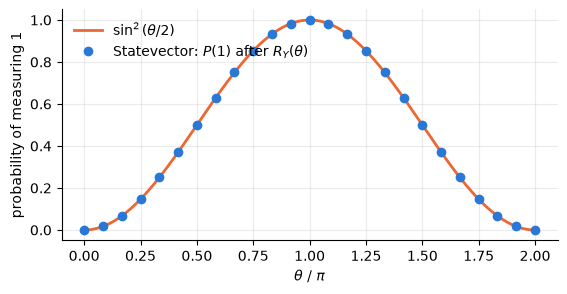

In [12]:
theta = np.pi / 3
ry_circ = QuantumCircuit(1)
ry_circ.ry(theta, 0)
sv = Statevector(ry_circ)
print(sv)
print("probabilities():", sv.probabilities(), "| sin²(θ/2) =", round(np.sin(theta / 2) ** 2, 4))
print("<Z> =", round(sv.expectation_value(SparsePauliOp("Z")).real, 4), "= cos θ")

thetas = np.linspace(0, 2 * np.pi, 25)
p1_sim = [Statevector.from_label("0").evolve(RYGate(t)).probabilities()[1] for t in thetas]
grid = np.linspace(0, 2 * np.pi, 400)

fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.plot(grid / np.pi, np.sin(grid / 2) ** 2, color="#eb6834", lw=2, label=r"$\sin^2(\theta/2)$")
ax.plot(thetas / np.pi, p1_sim, "o", color="#2a78d6", ms=6, label=r"Statevector: $P(1)$ after $R_Y(\theta)$")
ax.set_xlabel(r"$\theta\ /\ \pi$")
ax.set_ylabel("probability of measuring 1")
ax.grid(alpha=0.25)
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [13]:
multi = QuantumCircuit(3)
multi.h(0)
multi.cx(0, 1)
multi.x(2)
sv3 = Statevector(multi)
print("probabilities_dict:", sv3.probabilities_dict())   # keys read q2 q1 q0
print("marginal on qubit 0:", sv3.probabilities([0]))
print("marginal on qubit 2:", sv3.probabilities([2]))
print("<Z0 Z1> =", round(sv3.expectation_value(SparsePauliOp("IZZ")).real, 4))
sv3.seed(11)
print("1000 samples:", sv3.sample_counts(1000))

probabilities_dict: {'100': 0.4999999999999999, '111': 0.4999999999999999}
marginal on qubit 0: [0.5 0.5]
marginal on qubit 2: [0. 1.]
<Z0 Z1> = 1.0
1000 samples: {'100': 520, '111': 480}


### Multi-qubit gates

| Gate | Method | Notes |
|---|---|---|
| `CXGate` (CNOT) | `qc.cx(control, target)` | control is the first argument |
| `CYGate`, `CZGate`, `CHGate` | `qc.cy`, `qc.cz`, `qc.ch` | `cz` is symmetric: `cz(0, 1) == cz(1, 0)` |
| `CPhaseGate`, `CRXGate`, `CRYGate`, `CRZGate` | `qc.cp(λ, c, t)`, `qc.crx/cry/crz(θ, c, t)` | angle first |
| `SwapGate`, `iSwapGate` | `qc.swap(a, b)`, `qc.iswap(a, b)` | SWAP = three CX gates |
| `CCXGate` (Toffoli) | `qc.ccx(c1, c2, t)` | non-Clifford |
| `CSwapGate` (Fredkin) | `qc.cswap(c, a, b)` | swaps `a` and `b` if `c` is 1 |
| `MCXGate` | `qc.mcx([c0, c1, ...], t)` | any number of controls |
| `MCPhaseGate` | `qc.mcp(λ, [controls], t)` | multi-controlled phase |
| any gate | `gate.control(n, ctrl_state=...)` | returns a `ControlledGate` (or the matching standard class) |

CX in Qiskit's ordering. Matrices use the basis $\lvert q_1 q_0\rangle$. With the control on qubit 0, `qc.cx(0, 1)` swaps $\lvert 01\rangle \leftrightarrow \lvert 11\rangle$. The "textbook" CNOT matrix, with the control as the left factor, is `qc.cx(1, 0)` in Qiskit.

In [14]:
cx_circ = QuantumCircuit(2)
cx_circ.cx(0, 1)
print("Operator of qc.cx(0, 1):\n", Operator(cx_circ).data.real)
cx_rev = QuantumCircuit(2)
cx_rev.cx(1, 0)
print("Operator of qc.cx(1, 0):\n", Operator(cx_rev).data.real)
for label in ["00", "01", "10", "11"]:
    out = Statevector.from_label(label).evolve(cx_circ).probabilities_dict()
    print(f"cx(0, 1): |{label}> -> |{max(out, key=out.get)}>")

mq = QuantumCircuit(4)
mq.cx(0, 1)
mq.cz(1, 2)
mq.cy(0, 3)
mq.swap(2, 3)
mq.ccx(0, 1, 2)
mq.cswap(0, 2, 3)
mq.cp(np.pi / 4, 1, 3)
mq.cry(0.3, 0, 2)
mq.mcx([0, 1, 2], 3)
print(mq.draw(fold=-1))
print(dict(mq.count_ops()))

Operator of qc.cx(0, 1):
 [[1. 0. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]
 [0. 1. 0. 0.]]
Operator of qc.cx(1, 0):
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]]
cx(0, 1): |00> -> |00>
cx(0, 1): |01> -> |11>
cx(0, 1): |10> -> |10>
cx(0, 1): |11> -> |01>
                                                      
q_0: ──■───────■───────■───■───────────────■───────■──
     ┌─┴─┐     │       │   │               │       │  
q_1: ┤ X ├─■───┼───────■───┼──■────────────┼───────■──
     └───┘ │   │     ┌─┴─┐ │  │       ┌────┴────┐  │  
q_2: ──────■───┼───X─┤ X ├─X──┼───────┤ Ry(0.3) ├──■──
             ┌─┴─┐ │ └───┘ │  │P(π/4) └─────────┘┌─┴─┐
q_3: ────────┤ Y ├─X───────X──■──────────────────┤ X ├
             └───┘                               └───┘
{'cx': 1, 'cz': 1, 'cy': 1, 'swap': 1, 'ccx': 1, 'cswap': 1, 'cp': 1, 'cry': 1, 'mcx': 1}


Do not assume the textbook CNOT matrix $\begin{pmatrix}1&0&0&0\\0&1&0&0\\0&0&0&1\\0&0&1&0\end{pmatrix}$ belongs to `qc.cx(0, 1)`. In Qiskit, that matrix is `qc.cx(1, 0)`, because qubit 0 is the rightmost (least significant) bit.

#### Controlled versions, `ctrl_state`, and identities worth memorising

`gate.control(num_ctrl_qubits, ctrl_state=None)` adds controls. The new control qubits come first in the qubit list, and the original gate's qubits follow. Qiskit returns the matching standard class when one exists (`XGate().control(2)` is a `CCXGate`). `ctrl_state` sets the control pattern as a bitstring or integer, and it is little-endian too: `ctrl_state="01"` means control qubit 0 must be $\lvert 1\rangle$ and control qubit 1 must be $\lvert 0\rangle$.

| Identity | Why it matters |
|---|---|
| $HXH = Z$, $HZH = X$, $HYH = -Y$ | $H$ swaps the X and Z bases |
| $CZ = H_1\,CX_{0\to1}\,H_1 = H_0\,CX_{1\to0}\,H_0$ (H on the target) | CZ from CX; CZ is symmetric in its qubits |
| $(H\otimes H)\,CX_{0\to1}\,(H\otimes H) = CX_{1\to0}$ | Hadamards reverse a CNOT |
| $SWAP = CX_{0\to1}\,CX_{1\to0}\,CX_{0\to1}$ | three CNOTs |
| $CY_{0\to1} = S_1\,CX_{0\to1}\,S_1^\dagger$ | as a circuit: `sdg(1)`, `cx(0, 1)`, `s(1)` |

In [15]:
for gate, n in [(XGate(), 1), (XGate(), 2), (XGate(), 3), (ZGate(), 1), (HGate(), 1), (RYGate(0.3), 1), (SwapGate(), 1)]:
    cg = gate.control(n)
    print(f"{gate.name}.control({n}) -> {cg.base_class.__name__:<9} name={cg.name!r:<7} qubits={cg.num_qubits}")

open_ccx = XGate().control(2, ctrl_state="01")   # fires when q0 = 1 and q1 = 0
truth = QuantumCircuit(3)
truth.append(open_ccx, [0, 1, 2])                # controls: q0, q1; target: q2
for label in ["000", "001", "010", "011"]:
    out = Statevector.from_label(label).evolve(truth).probabilities_dict()
    print(f"|{label}> -> |{max(out, key=out.get)}>")

# A whole sub-circuit can be controlled too (it must be unitary: no measurements)
bell_gate = bell_circ.to_gate()                  # the gate takes the circuit's name, 'bell'
c_bell = bell_gate.control(1)
print(type(c_bell).__name__, c_bell.name, c_bell.num_qubits)


def circuit_op(n, *steps):
    # Operator of a small circuit given as (method, *args) steps.
    circ = QuantumCircuit(n)
    for name, *args in steps:
        getattr(circ, name)(*args)
    return Operator(circ)


checks = {
    "H X H == Z": circuit_op(1, ("h", 0), ("x", 0), ("h", 0)) == Operator(ZGate()),
    "H Z H == X": circuit_op(1, ("h", 0), ("z", 0), ("h", 0)) == Operator(XGate()),
    "H Y H == -Y": circuit_op(1, ("h", 0), ("y", 0), ("h", 0)) == -Operator(YGate()),
    "cz(0,1) == cz(1,0)": circuit_op(2, ("cz", 0, 1)) == circuit_op(2, ("cz", 1, 0)),
    "H_1 CX_{0->1} H_1 == CZ": circuit_op(2, ("h", 1), ("cx", 0, 1), ("h", 1)) == Operator(CZGate()),
    "H_0 CX_{1->0} H_0 == CZ": circuit_op(2, ("h", 0), ("cx", 1, 0), ("h", 0)) == Operator(CZGate()),
    "(H⊗H) cx(0,1) (H⊗H) == cx(1,0)": circuit_op(2, ("h", 0), ("h", 1), ("cx", 0, 1), ("h", 0), ("h", 1))
        == circuit_op(2, ("cx", 1, 0)),
    "sdg(1) cx(0,1) s(1) == cy(0,1)": circuit_op(2, ("sdg", 1), ("cx", 0, 1), ("s", 1)) == Operator(CYGate()),
}
print()
for name, ok in checks.items():
    print(f"{name:<34} {ok}")

x.control(1) -> CXGate    name='cx'    qubits=2
x.control(2) -> CCXGate   name='ccx'   qubits=3
x.control(3) -> MCXGate   name='mcx'   qubits=4
z.control(1) -> CZGate    name='cz'    qubits=2
h.control(1) -> CHGate    name='ch'    qubits=2
ry.control(1) -> CRYGate   name='cry'   qubits=2
swap.control(1) -> CSwapGate name='cswap' qubits=3
|000> -> |000>
|001> -> |101>
|010> -> |010>
|011> -> |011>
ControlledGate cbell 3

H X H == Z                         True
H Z H == X                         True
H Y H == -Y                        True
cz(0,1) == cz(1,0)                 True
H_1 CX_{0->1} H_1 == CZ            True
H_0 CX_{1->0} H_0 == CZ            True
(H⊗H) cx(0,1) (H⊗H) == cx(1,0)     True
sdg(1) cx(0,1) s(1) == cy(0,1)     True


#### More from the `Operator` class: fidelities, operators in circuits, linear combinations

> **Optional extension.** Operator fidelity and linear combinations. You can skip this block, including its starter/check cells and solutions, and [continue with the core path](#s1-resume-45). Later core code does not require this block.

- `process_fidelity(A, B)` and `average_gate_fidelity(A, B)` (from `qiskit.quantum_info`) measure how close two operations are. For unitaries they ignore global phase: $SX$ vs $R_X(\pi/2)$ gives 1, even though `==` is `False`.
- A circuit can hold operators directly. `qc.append(Operator(...), qargs)` stores a `UnitaryGate` named `unitary` (the same as `qc.unitary(matrix, qargs)`), and `qc.append(Pauli(...), qargs)` stores a `PauliGate` named `pauli`.
- Operators support `+`, `-` and scalar `*`, but a linear combination of unitaries is generally not unitary. Check it with `is_unitary()` before you use it as a gate.

In [16]:
a, b = Operator(SXGate()), Operator(RXGate(np.pi / 2))
print("SX == RX(pi/2):", a == b,
      "| process_fidelity:", round(process_fidelity(a, b), 6),
      "| average_gate_fidelity:", round(average_gate_fidelity(a, b), 6))
x_op, z_op = Operator(XGate()), Operator(ZGate())
print("X vs Z       : process_fidelity:", round(process_fidelity(x_op, z_op), 6),
      "| average_gate_fidelity:", round(average_gate_fidelity(x_op, z_op), 6))

op_circ = QuantumCircuit(2)
op_circ.append(Operator(CXGate()), [0, 1])   # stored as a UnitaryGate
op_circ.append(Pauli("XZ"), [0, 1])          # stored as a PauliGate
print([(ci.operation.name, type(ci.operation).__name__) for ci in op_circ.data])
print("circuit still equals CX then XZ:", Operator(op_circ) == Operator(Pauli("XZ")).dot(Operator(CXGate())))

mix = 0.5 * x_op + 0.5 * z_op
print("0.5·X + 0.5·Z unitary?", mix.is_unitary())
print("(X + Z)/√2 unitary?   ", ((x_op + z_op) * float(1 / np.sqrt(2))).is_unitary(),
      "(it is H:", ((x_op + z_op) * float(1 / np.sqrt(2))) == Operator(HGate()), ")")

SX == RX(pi/2): False | process_fidelity: 1.0 | average_gate_fidelity: 1.0
X vs Z       : process_fidelity: 0.0 | average_gate_fidelity: 0.333333
[('unitary', 'UnitaryGate'), ('pauli', 'PauliGate')]
circuit still equals CX then XZ: True
0.5·X + 0.5·Z unitary? False
(X + Z)/√2 unitary?    True (it is H: True )


<a id="s1-resume-45"></a>

### Circuit mechanics

| Method | What it does | Watch out for |
|---|---|---|
| `qc.compose(other, qubits=None, front=False, inplace=False)` | inlines `other`'s gates into a copy of `qc` | returns a new circuit unless `inplace=True` (then it returns `None`); `other` cannot be wider than `qc`; `qubits=[a, b]` maps `other`'s qubit 0 → `a`, 1 → `b`; `front=True` puts `other` before `qc` |
| `qc.append(instruction, qargs)` | adds one instruction in place | a circuit appended this way becomes a single opaque box |
| `top.tensor(bottom)` | side-by-side circuit $\text{top}\otimes\text{bottom}$ | `bottom` takes the low qubit indices |
| `qc.inverse()` | $U^\dagger$: order reversed and every gate inverted | |
| `qc.reverse_ops()` | order reversed only | not the inverse |
| `qc.power(n)` / `qc.repeat(n)` | $n$ copies (as boxed sub-circuits) | `power(x, matrix_power=True)` builds one `UnitaryGate` from the matrix power |
| `qc.to_gate()` / `qc.to_instruction()` | package a circuit for reuse | `to_gate()` fails if the circuit has measurements, resets, barriers or classical bits |
| `qc.control(n)` / `gate.control(n)` | controlled version | only for unitary content |
| `qc.decompose(gates_to_decompose=None, reps=1)` | expands composite instructions by one level per rep | |
| `qc.depth()`, `qc.size()`, `qc.width()` | critical-path length, number of operations, qubits + clbits | barriers are not counted in `size` or `depth` |
| `qc.count_ops()`, `qc.num_nonlocal_gates()` | operation histogram, number of gates on ≥ 2 qubits | `count_ops` does include barriers and measurements |

In [17]:
base = QuantumCircuit(3)
base.cx(0, 1)
block = QuantumCircuit(2, name="blk")
block.h(0)
block.cz(0, 1)

after = base.compose(block, qubits=[2, 0])               # block q0 -> q2, block q1 -> q0; placed after base
before = base.compose(block, qubits=[2, 0], front=True)  # same mapping, placed before base
print("compose (default, appended at the end):")
print(after.draw())
print("compose(front=True):")
print(before.draw())
print("base is unchanged:", base.size(), "instruction | inplace=True returns:",
      base.copy().compose(block, qubits=[1, 2], inplace=True))

boxed = QuantumCircuit(3)
boxed.cx(0, 1)
boxed.append(block.to_gate(), [2, 0])      # one opaque instruction named 'blk'
print("append  ->", dict(boxed.count_ops()), "| compose ->", dict(after.count_ops()),
      "| same unitary:", Operator(boxed) == Operator(after))

top = QuantumCircuit(1)
top.x(0)
bottom = QuantumCircuit(2)
bottom.h(0)
bottom.cx(0, 1)
side_by_side = top.tensor(bottom)           # bottom on qubits 0-1, top on qubit 2
print("top.tensor(bottom):")
print(side_by_side.draw())
print("matches Operator.tensor:", Operator(side_by_side) == Operator(top).tensor(Operator(bottom)))

compose (default, appended at the end):
             
q_0: ──■───■─
     ┌─┴─┐ │ 
q_1: ┤ X ├─┼─
     ├───┤ │ 
q_2: ┤ H ├─■─
     └───┘   
compose(front=True):
                  
q_0: ──────■───■──
           │ ┌─┴─┐
q_1: ──────┼─┤ X ├
     ┌───┐ │ └───┘
q_2: ┤ H ├─■──────
     └───┘        
base is unchanged: 1 instruction | inplace=True returns: None
append  -> {'cx': 1, 'blk': 1} | compose -> {'cx': 1, 'h': 1, 'cz': 1} | same unitary: True
top.tensor(bottom):
     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
     ┌───┐└───┘
q_2: ┤ X ├─────
     └───┘     
matches Operator.tensor: True


In [18]:
seq = QuantumCircuit(1)
seq.h(0)
seq.sx(0)
seq.s(0)
print("original   :", [ci.operation.name for ci in seq.data])
print("inverse    :", [ci.operation.name for ci in seq.inverse().data])
print("reverse_ops:", [ci.operation.name for ci in seq.reverse_ops().data])
print("inverse == U†:", Operator(seq.inverse()) == Operator(seq).adjoint())

t_only = QuantumCircuit(1, name="tcirc")
t_only.t(0)
print("\npower(2) boxes   :", dict(t_only.power(2).count_ops()), "-> decomposed", dict(t_only.power(2).decompose().count_ops()))
print("repeat(3) boxes  :", dict(t_only.repeat(3).count_ops()), "-> decomposed", dict(t_only.repeat(3).decompose().count_ops()))
print("matrix_power=True:", dict(t_only.power(2, matrix_power=True).count_ops()))
print("T^2 == S:", Operator(t_only.power(2)) == Operator(SGate()))
print("TGate().power(2) ->", TGate().power(2).name, TGate().power(2).params)   # a PhaseGate(pi/2), not an SGate object

measured = QuantumCircuit(1, 1, name="measured")
measured.h(0)
measured.measure(0, 0)
print("\nto_instruction ->", type(measured.to_instruction()).__name__)
try:
    measured.to_gate()
except QiskitError as err:
    print("to_gate        ->", err)

layered = QuantumCircuit(3)
layered.append(bell_gate, [0, 1])
layered.append(MCXGate(2), [0, 1, 2])
layered.append(QFTGate(2), [1, 2])
print("\nas built         :", dict(layered.count_ops()))
print("decompose()      :", dict(layered.decompose().count_ops()))
print("decompose('bell'):", dict(layered.decompose("bell").count_ops()))

original   : ['h', 'sx', 's']
inverse    : ['sdg', 'sxdg', 'h']
reverse_ops: ['s', 'sx', 'h']
inverse == U†: True

power(2) boxes   : {'tcirc': 2} -> decomposed {'t': 2}
repeat(3) boxes  : {'tcirc': 3} -> decomposed {'t': 3}
matrix_power=True: {'unitary': 1}
T^2 == S: True
TGate().power(2) -> p [1.5707963267948966]

to_instruction -> Instruction
to_gate        -> 'Circuit with classical bits cannot be converted to gate.'

as built         : {'bell': 1, 'ccx': 1, 'qft': 1}
decompose()      : {'cx': 7, 'h': 5, 't': 4, 'tdg': 3, 'cp': 1, 'swap': 1}
decompose('bell'): {'h': 1, 'cx': 1, 'ccx': 1, 'qft': 1}


In [19]:
metrics = QuantumCircuit(3, 3)
metrics.h(0)
metrics.cx(0, 1)
metrics.cx(1, 2)
metrics.x(0)
metrics.barrier()
metrics.measure(range(3), range(3))
print(metrics.draw())
print("depth:", metrics.depth(), "| size:", metrics.size(), "| width:", metrics.width(),
      "| num_qubits:", metrics.num_qubits, "| num_clbits:", metrics.num_clbits)
print("count_ops:", dict(metrics.count_ops()))
print("num_nonlocal_gates:", metrics.num_nonlocal_gates())
print("two-qubit depth:", metrics.depth(lambda ci: ci.operation.num_qubits == 2))

     ┌───┐     ┌───┐ ░ ┌─┐      
q_0: ┤ H ├──■──┤ X ├─░─┤M├──────
     └───┘┌─┴─┐└───┘ ░ └╥┘┌─┐   
q_1: ─────┤ X ├──■───░──╫─┤M├───
          └───┘┌─┴─┐ ░  ║ └╥┘┌─┐
q_2: ──────────┤ X ├─░──╫──╫─┤M├
               └───┘ ░  ║  ║ └╥┘
c: 3/═══════════════════╩══╩══╩═
                        0  1  2 
depth: 4 | size: 7 | width: 6 | num_qubits: 3 | num_clbits: 3
count_ops: {'measure': 3, 'cx': 2, 'h': 1, 'x': 1, 'barrier': 1}
num_nonlocal_gates: 2
two-qubit depth: 2


`width()` counts qubits plus classical bits, whereas `num_qubits` counts only qubits. `size()` skips barriers, and `count_ops()` lists them. `depth()` is the length of the longest path through the circuit, with each gate counting as one layer regardless of how many qubits it touches.

### Circuit library building blocks and feature maps

> **Study priority.** First-pass focus: recognise standard gates, reusable parameterized circuits and feature maps, and inspect their parameters. Memorising the default feature-map expansion is a second-pass task.

`qiskit.circuit.library` provides three kinds of objects:
- Standard gates as `Gate` classes (`XGate`, `CXGate`, `RZZGate`, …; `get_standard_gate_name_mapping()` lists them) plus more abstract gates such as `MCXGate`, `QFTGate`, `UnitaryGate`, `PauliGate`, `DiagonalGate`, `StatePreparation`.
- Functions that return a `QuantumCircuit` (added in Qiskit 1.3 and the recommended form): `real_amplitudes`, `efficient_su2`, `n_local`, `z_feature_map`, `zz_feature_map`, `pauli_feature_map`, `quantum_volume`, `grover_operator`, `phase_estimation`, and others. The variational ones (`real_amplitudes`, `efficient_su2`, `n_local`) are covered with parameterized circuits in Section 3.
- Legacy class forms of the same circuits are pending deprecation in Qiskit 2.0 (a `PendingDeprecationWarning`, since 1.3) and deprecated from 2.1. This notebook uses only the function forms.

If you meet a class name in older tutorials or study notes, rename it:

| Legacy class (pending deprecation) | Function to use |
|---|---|
| `ZFeatureMap` | `z_feature_map` |
| `ZZFeatureMap` | `zz_feature_map` |
| `PauliFeatureMap` | `pauli_feature_map` |
| `RealAmplitudes` | `real_amplitudes` |
| `EfficientSU2` | `efficient_su2` |
| `TwoLocal` / `NLocal` | `n_local` |
| `QFT` | `QFTGate` (a gate, not a circuit) |

None of these library circuits appears in IBM's official sample test; know the function names and what the feature maps do.

Data encoding. Quantum ML models first load classical data into a state. For the exam, know the idea behind each encoding and the Qiskit functions.

| Encoding | Idea | Qubits for $N$ features | Qiskit tools |
|---|---|---|---|
| Basis | bits → a computational basis state | bits per feature × $N$ | `qc.x`, `qc.prepare_state("0101")` (rightmost bit → qubit 0) |
| Amplitude | normalized vector → amplitudes | $\lceil\log_2 N\rceil$ | `StatePreparation` / `qc.prepare_state(vec)` (a unitary gate) or `qc.initialize(vec)` (adds a reset, so it is not a `Gate`) |
| Angle | $x_k \to R_Y(x_k)$ on qubit $k$ | $N$ | `qc.ry` |
| Phase | $H$, then $P(x_k)$ | $N$ | `qc.h`, `qc.p` |
| Dense angle | two features per qubit, $R_Y$ then $R_Z$ | $N/2$ | `qc.ry`, `qc.rz` |
| Feature map | repeated layers of phase encoding plus entangling data terms | $N$ | `z_feature_map`, `zz_feature_map`, `pauli_feature_map` |

The three feature-map functions share the signature `(feature_dimension, reps=2, entanglement="full", alpha=2.0, ..., parameter_prefix="x", insert_barriers=False)` and return a parameterized `QuantumCircuit` with a `ParameterVector` named `x`:

- `z_feature_map`: each repetition is $H$ on every qubit, then $P(\alpha\, x_i)$, which is $P(2x_i)$ with the default `alpha=2.0`. There is no entanglement, even though `entanglement` exists as a parameter.
- `zz_feature_map`: the same single-qubit layer, then for each pair $(i, j)$ allowed by `entanglement` the block $CX_{ij}\; P\big(2(\pi - x_i)(\pi - x_j)\big)_j\; CX_{ij}$, which implements $e^{-i\phi\, Z_iZ_j/2}$ up to a global phase.
- `pauli_feature_map(paulis=[...])`: the generalization to any Pauli strings, for example `["X", "ZZ"]`. The default `paulis=None` means `["Z", "ZZ"]`, which is exactly `zz_feature_map`.

In [20]:
from qiskit.circuit import Gate
names = get_standard_gate_name_mapping()
std_gates = sorted(k for k, v in names.items() if isinstance(v, Gate))
non_gates = sorted(set(names) - set(std_gates))
print(len(std_gates), "standard gates plus the non-gate instructions", non_gates)
print("e.g.", std_gates[:14])

print()
zfm = z_feature_map(feature_dimension=2, reps=1)
print(zfm.draw())
print("name:", zfm.name, "| parameters:", list(zfm.parameters))

zzfm = zz_feature_map(feature_dimension=3, reps=1, entanglement="linear")
print(zzfm.draw(fold=-1))

pfm = pauli_feature_map(feature_dimension=2, reps=1, paulis=["X", "ZZ"])
print(pfm.draw(fold=-1))   # X terms are implemented as H · P · H

51 standard gates plus the non-gate instructions ['delay', 'measure', 'reset']
e.g. ['c3sx', 'ccx', 'ccz', 'ch', 'cp', 'crx', 'cry', 'crz', 'cs', 'csdg', 'cswap', 'csx', 'cu', 'cu1']



   ┌───┐┌─────────────┐
0: ┤ H ├┤ P(2.0*x[0]) ├
   ├───┤├─────────────┤
1: ┤ H ├┤ P(2.0*x[1]) ├
   └───┘└─────────────┘
name: ZFeatureMap | parameters: [ParameterVectorElement(x[0]), ParameterVectorElement(x[1])]
   ┌───┐┌─────────────┐                                                                                    
0: ┤ H ├┤ P(2.0*x[0]) ├──■────────────────────────────────────■────────────────────────────────────────────
   ├───┤├─────────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐                                          
1: ┤ H ├┤ P(2.0*x[1]) ├┤ X ├┤ P(2.0*(x[0] - π)*(x[1] - π)) ├┤ X ├──■────────────────────────────────────■──
   ├───┤├─────────────┤└───┘└──────────────────────────────┘└───┘┌─┴─┐┌──────────────────────────────┐┌─┴─┐
2: ┤ H ├┤ P(2.0*x[2]) ├──────────────────────────────────────────┤ X ├┤ P(2.0*(x[1] - π)*(x[2] - π)) ├┤ X ├
   └───┘└─────────────┘                                          └───┘└──────────────────────────────┘└───┘
   ┌───┐┌───┐┌─────────────┐┌──

In [21]:
x_data = [0.4, 1.1]
default_pauli = pauli_feature_map(2, reps=1).assign_parameters(x_data)
zz_bound = zz_feature_map(2, reps=1).assign_parameters(x_data)
print("pauli_feature_map default == zz_feature_map:", Operator(default_pauli) == Operator(zz_bound))

for ent in ["linear", "reverse_linear", "circular", "full"]:
    fm = zz_feature_map(4, reps=1, entanglement=ent)
    print(f"4 features, entanglement={ent!r:<17} cx gates = {fm.count_ops()['cx']:>2}, parameters = {fm.num_parameters}")

fm2 = zz_feature_map(2, reps=2)
print("\nreps=2 bound to", x_data, "->", Statevector(fm2.assign_parameters(x_data)).probabilities_dict(decimals=3))

pauli_feature_map default == zz_feature_map: True
4 features, entanglement='linear'          cx gates =  6, parameters = 4
4 features, entanglement='reverse_linear'  cx gates =  6, parameters = 4
4 features, entanglement='circular'        cx gates =  8, parameters = 4
4 features, entanglement='full'            cx gates = 12, parameters = 4

reps=2 bound to [0.4, 1.1] -> {'00': 0.153, '01': 0.289, '10': 0.416, '11': 0.142}


`reps` does not add parameters. The same $x_i$ is reused in every repetition, so `num_parameters` always equals `feature_dimension`. Also, the single-qubit angle is $2x_i$ rather than $x_i$, because `alpha` defaults to `2.0`.

### Practice 1.3 — Target a measurement probability with `RY`

Choose `ex3_theta` so that measuring $R_Y(\theta)\lvert 0\rangle$ gives $P(1) = 0.9$ exactly. Then build `ex3_qc`, a 1-qubit circuit that contains a single `ry(ex3_theta, 0)` gate.

In [ ]:
ex3_theta = None             # TODO: use P(1) = sin²(θ/2)
ex3_qc = QuantumCircuit(1)
# TODO: add the ry gate

In [ ]:
# Run this cell to check your answer
assert ex3_theta is not None, "set ex3_theta"
assert dict(ex3_qc.count_ops()) == {"ry": 1}, "use exactly one ry gate"
assert np.isclose(float(ex3_qc.data[0].operation.params[0]), ex3_theta), "use ex3_theta as the angle"
assert np.allclose(Statevector(ex3_qc).probabilities(), [0.1, 0.9]), "P(1) should be 0.9"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex3_theta = 2 * np.arcsin(np.sqrt(0.9))
ex3_qc = QuantumCircuit(1)
ex3_qc.ry(ex3_theta, 0)
print(round(ex3_theta, 4), Statevector(ex3_qc).probabilities())
```

$P(1) = \sin^2(\theta/2) = 0.9$ gives $\theta = 2\arcsin\sqrt{0.9} \approx 2.4981$ rad. $\theta' = 2\pi - 2.4981$ also works, because only $\sin^2$ matters.

</details>

### Practice 1.4 — Gate identities: CZ and SWAP from CX

1. Using only `h` and `cx`, build a 2-qubit circuit `ex4_cz` with `Operator(ex4_cz) == Operator(CZGate())`.
2. Using exactly three `cx` gates, build `ex4_swap` with `Operator(ex4_swap) == Operator(SwapGate())`.

In [ ]:
ex4_cz = QuantumCircuit(2)
# TODO: h and cx only

ex4_swap = QuantumCircuit(2)
# TODO: three cx gates

In [ ]:
# Run this cell to check your answer
assert set(ex4_cz.count_ops()) <= {"h", "cx"}, "ex4_cz may only use h and cx"
assert Operator(ex4_cz) == Operator(CZGate()), "ex4_cz is not a CZ (put the H gates on the CX target)"
assert dict(ex4_swap.count_ops()) == {"cx": 3}, "ex4_swap must use exactly three cx gates"
assert Operator(ex4_swap) == Operator(SwapGate()), "ex4_swap is not a SWAP (alternate the CX direction)"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex4_cz = QuantumCircuit(2)
ex4_cz.h(1)
ex4_cz.cx(0, 1)
ex4_cz.h(1)

ex4_swap = QuantumCircuit(2)
ex4_swap.cx(0, 1)
ex4_swap.cx(1, 0)
ex4_swap.cx(0, 1)
print(dict(ex4_cz.count_ops()), dict(ex4_swap.count_ops()))
```

Conjugating the target of a CX with $H$ turns its X into $HXH = Z$, which gives CZ. Because CZ is symmetric, `h(0); cx(1, 0); h(0)` works as well. Putting the H gates on the control qubit does not give CZ. SWAP needs three alternating CNOTs, $CX_{0\to1}CX_{1\to0}CX_{0\to1}$.

</details>

### Practice 1.5 — Get the global phase exactly right

> **Optional extension.** Practice 1.5: derive an exact phase correction. You can skip this block, including its starter/check cells and solutions, and [continue with the core path](#s1-resume-64). Later core code does not require this block.

The sequence $R_Z(\pi/2)\;SX\;R_Z(\pi/2)$ implements the Hadamard gate up to a global phase, which is how IBM hardware runs `h`. In the starter circuit, set `ex5_qc.global_phase` so that `Operator(ex5_qc) == Operator(HGate())` holds exactly.

Hint: compare one non-zero matrix entry of the two operators and take `np.angle` of the ratio.

In [ ]:
ex5_qc = QuantumCircuit(1)
ex5_qc.rz(np.pi / 2, 0)
ex5_qc.sx(0)
ex5_qc.rz(np.pi / 2, 0)
ex5_qc.global_phase = 0.0   # TODO: replace 0.0 with the correct phase (radians)

In [ ]:
# Run this cell to check your answer
assert dict(ex5_qc.count_ops()) == {"rz": 2, "sx": 1}, "keep exactly rz(pi/2), sx, rz(pi/2)"
assert Operator(ex5_qc).equiv(Operator(HGate())), "the gate sequence should equal H up to phase"
assert Operator(ex5_qc) == Operator(HGate()), "right gates, but the global phase is still off"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex5_qc = QuantumCircuit(1)
ex5_qc.rz(np.pi / 2, 0)
ex5_qc.sx(0)
ex5_qc.rz(np.pi / 2, 0)
ex5_ratio = Operator(HGate()).data[0, 0] / Operator(ex5_qc).data[0, 0]
ex5_qc.global_phase = np.angle(ex5_ratio)   # = pi/4
print(round(ex5_qc.global_phase / np.pi, 4), "* pi")
```

$R_Z(\pi/2) = e^{-i\pi/4}S$, so the sequence equals $e^{-i\pi/2}\,S\,SX\,S = e^{-i\pi/4}H$. A global phase of $+\pi/4$ cancels this factor. Without it, `equiv` is already `True` but `==` is `False`, which is the same distinction as $T\lvert 1\rangle$ vs $\lvert 1\rangle$.

</details>

<a id="s1-resume-64"></a>

### Practice 1.6 — `compose` with a qubit map and `front=True`, then invert

Starting from an empty 3-qubit circuit `ex6_qc`:
1. compose the given 2-qubit `ex6_block` so that block qubit 0 → circuit qubit 2 and block qubit 1 → circuit qubit 0;
2. then put an `X` on qubit 1 at the front of the circuit, using a 1-qubit circuit and `compose(..., front=True)`;
3. store the inverse circuit in `ex6_inv`.

Remember that `compose` returns a new circuit unless you pass `inplace=True`.

In [ ]:
ex6_block = QuantumCircuit(2, name="blk")
ex6_block.h(0)
ex6_block.cx(0, 1)

ex6_qc = QuantumCircuit(3)
# TODO 1: compose ex6_block with the qubit map described above
# TODO 2: prepend X on qubit 1 with front=True
ex6_inv = None  # TODO 3

In [ ]:
# Run this cell to check your answer
ex6_ref = QuantumCircuit(3)
ex6_ref.x(1)
ex6_ref.h(2)
ex6_ref.cx(2, 0)
assert ex6_qc.size() == 3, "ex6_qc should contain exactly x, h, cx (did you forget to keep compose's return value?)"
assert ex6_qc.data[0].operation.name == "x", "the X must come first (front=True)"
assert Operator(ex6_qc) == Operator(ex6_ref), "check the qubits= mapping"
assert ex6_inv is not None and Operator(ex6_inv) == Operator(ex6_ref).adjoint(), "ex6_inv must be ex6_qc.inverse()"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex6_block = QuantumCircuit(2, name="blk")
ex6_block.h(0)
ex6_block.cx(0, 1)

ex6_qc = QuantumCircuit(3)
ex6_qc = ex6_qc.compose(ex6_block, qubits=[2, 0])
ex6_x = QuantumCircuit(1)
ex6_x.x(0)
ex6_qc = ex6_qc.compose(ex6_x, qubits=[1], front=True)
ex6_inv = ex6_qc.inverse()
print(ex6_qc.draw())
```

`qubits=[2, 0]` is read position by position: the other circuit's qubit 0 goes to 2 and its qubit 1 goes to 0, so `h(0)` becomes `h(2)` and `cx(0, 1)` becomes `cx(2, 0)`. `front=True` puts the X before everything else. `inverse()` reverses the order and inverts each gate (here all three are self-inverse).

</details>

### Practice 1.7 — Rebuild `zz_feature_map` by hand

> **Optional extension.** Practice 1.7: rebuild a feature map. You can skip this block, including its starter/check cells and solutions, and [continue with the core path](#s1-resume-72). Later core code does not require this block.

For the data point $x = (0.4, 1.1)$, build `ex7_manual` from explicit `h`, `p` and `cx` gates (numbers, no parameters) so that

`Operator(ex7_manual) == Operator(zz_feature_map(2, reps=1).assign_parameters([0.4, 1.1]))`.

Use the defaults: `alpha = 2.0` and the ZZ data map $(\pi - x_0)(\pi - x_1)$.

In [ ]:
ex7_x = [0.4, 1.1]
ex7_manual = QuantumCircuit(2)
# TODO: Hadamard layer, single-qubit phases, then the CX-P-CX block

In [ ]:
# Run this cell to check your answer
ex7_ref = zz_feature_map(2, reps=1).assign_parameters([0.4, 1.1])
assert ex7_manual.num_parameters == 0, "use numbers, not Parameters"
assert set(ex7_manual.count_ops()) <= {"h", "p", "cx"}, "use only h, p and cx"
assert Operator(ex7_manual) == Operator(ex7_ref), "compare your angles with 2*x_i and 2*(pi-x0)*(pi-x1)"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex7_x = [0.4, 1.1]
ex7_manual = QuantumCircuit(2)
ex7_manual.h([0, 1])
ex7_manual.p(2 * ex7_x[0], 0)
ex7_manual.p(2 * ex7_x[1], 1)
ex7_manual.cx(0, 1)
ex7_manual.p(2 * (np.pi - ex7_x[0]) * (np.pi - ex7_x[1]), 1)
ex7_manual.cx(0, 1)
print(ex7_manual.draw(fold=-1))
```

One repetition of `zz_feature_map` is $H^{\otimes 2}$, then $P(2x_0)\otimes P(2x_1)$, then $CX_{01}\,P\big(2(\pi-x_0)(\pi-x_1)\big)_1\,CX_{01}$. The factor 2 is `alpha`. Forgetting it (using $P(x_i)$) is the most common mistake.

</details>

<a id="s1-resume-72"></a>

Q1.5. In Qiskit's basis ordering $\lvert q_1 q_0\rangle$, which pair of basis states does the operator of

```python
qc = QuantumCircuit(2)
qc.cx(0, 1)
```

exchange?

A. $\lvert 10\rangle \leftrightarrow \lvert 11\rangle$

B. $\lvert 01\rangle \leftrightarrow \lvert 11\rangle$

C. $\lvert 00\rangle \leftrightarrow \lvert 10\rangle$

D. $\lvert 01\rangle \leftrightarrow \lvert 10\rangle$

<details>
<summary>Show answer</summary>

Answer: B

The control is qubit 0, the rightmost bit. The target (qubit 1, left bit) flips only when that bit is 1: $\lvert 01\rangle \to \lvert 11\rangle$ and $\lvert 11\rangle \to \lvert 01\rangle$. Option A is the textbook CNOT with the control on the left bit, which in Qiskit is `qc.cx(1, 0)`. Option D is what a SWAP does.

</details>

Q1.6. The gate is appended to qubits `[0, 1, 2]` (controls `q0`, `q1`; target `q2`). What is printed?

```python
from qiskit import QuantumCircuit
from qiskit.circuit.library import XGate
from qiskit.quantum_info import Statevector

gate = XGate().control(2, ctrl_state="10")
qc = QuantumCircuit(3)
qc.append(gate, [0, 1, 2])
out = Statevector.from_label("010").evolve(qc)
print(max(out.probabilities_dict(), key=out.probabilities_dict().get))
```

A. `010`

B. `011`

C. `110`

D. `111`

<details>
<summary>Show answer</summary>

Answer: C

`ctrl_state="10"` is little-endian: control qubit 0 must be 0 and control qubit 1 must be 1. The input `'010'` has q0 = 0 and q1 = 1, so the pattern matches and the target q2 flips, giving `'110'`. Option A would be the answer if you read `"10"` left to right as (q0, q1) = (1, 0), because the pattern would then not match and nothing would flip.

</details>

Q1.7. `qc` contains an `h` gate followed by `measure(0, 0)`. Which call succeeds?

A. `qc.to_instruction()`

B. `qc.to_gate()`

C. `Operator(qc)`

D. `Statevector(qc)`

<details>
<summary>Show answer</summary>

Answer: A

A measurement is not unitary. `to_instruction()` accepts any content, but `to_gate()` requires a purely unitary circuit and raises `QiskitError`. `Operator(qc)` and `Statevector(qc)` also raise because they cannot apply an operation with classical bits. Remove the measurements (for example with `qc.remove_final_measurements()`) before building an operator or a state.

</details>

Q1.8. What is printed?

```python
from qiskit import QuantumCircuit

qc = QuantumCircuit(1)
qc.h(0)
qc.s(0)
qc.t(0)
print([inst.operation.name for inst in qc.inverse().data])
```

A. `['h', 'sdg', 'tdg']`

B. `['t', 's', 'h']`

C. `['tdg', 'sdg', 'h']`

D. `['h', 's', 't']`

<details>
<summary>Show answer</summary>

Answer: C

`inverse()` returns $U^\dagger = (T S H)^\dagger = H^\dagger S^\dagger T^\dagger$. In circuit order that is `tdg`, then `sdg`, then `h`, since $H$ is self-inverse. Option B is `reverse_ops()`, which reverses the order without inverting the gates. Option A inverts the gates but keeps the original order.

</details>

Q1.9. Which statement about `z_feature_map(3)` (all other arguments at their defaults) is correct?

> **Deeper API practice — optional on the first pass.** Exact feature-map defaults are a second-pass detail.

A. It has 6 parameters because `reps=2` by default.

B. It is built from `RZ(x[i])` gates, because `alpha` defaults to 1.

C. Because `entanglement='full'` by default, it contains CX–P–CX blocks on every qubit pair.

D. It has 3 parameters; each repetition applies $H$ and then $P(2x_i)$ to every qubit, and there are 2 repetitions by default.

<details>
<summary>Show answer</summary>

Answer: D

`z_feature_map` has one parameter per feature (`num_parameters == 3`), and the parameters are reused in every repetition. The defaults are `reps=2` and `alpha=2.0`, so the circuit is two layers of H followed by $P(2x_i)$ (drawn as `P(2.0*x[0])`, ...), giving 6 `h` and 6 `p` gates and no `cx`. The `entanglement` argument exists, but only Pauli strings with two or more qubits (as in `zz_feature_map`) create entangling blocks.

</details>

Q1.10. What is printed?

> **Deeper API practice — optional on the first pass.** This item combines three independent operator API details.

```python
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit.library import XGate, ZGate, SXGate, RXGate
from qiskit.quantum_info import Operator, Pauli, process_fidelity

qc = QuantumCircuit(2)
qc.append(Operator(XGate()), [0])
qc.append(Pauli("ZZ"), [0, 1])
mix = 0.5 * Operator(XGate()) + 0.5 * Operator(ZGate())
fid = process_fidelity(Operator(SXGate()), Operator(RXGate(np.pi / 2)))
print([inst.operation.name for inst in qc.data], mix.is_unitary(), round(fid, 3))
```

A. `['x', 'zz'] False 1.0`

B. `['unitary', 'pauli'] False 1.0`

C. `['unitary', 'pauli'] True 1.0`

D. `['unitary', 'unitary'] False 1.0`

<details>
<summary>Show answer</summary>

Answer: B

An appended `Operator` becomes a `UnitaryGate` named `unitary` (it is not recognised as `x`), and an appended `Pauli` becomes a `PauliGate` named `pauli`, so A and D are wrong. $\tfrac12(X+Z)$ has eigenvalues $\pm 1/\sqrt2$, so it is not unitary (C is wrong). $SX$ and $R_X(\pi/2)$ differ only by a global phase, which `process_fidelity` ignores, so the fidelity is 1.

</details>

<a id="s1-core-82"></a>

## Section review — exam-style questions

First pass: answer the unmarked questions. Items labelled **Optional extension** or **Deeper API practice** are a separate second pass; they are not prerequisites for moving to the next notebook.

Fourteen mixed-depth practice questions. The multi-select items say how many answers to choose. On the exam, a multi-select item scores only if every choice is correct.

R1. What is printed?

```python
from qiskit.quantum_info import Pauli

p = Pauli("XYZ")
print(p[0], p[2])
```

A. `X Z`

B. `X Y`

C. `Z X`

D. `Y Z`

<details>
<summary>Show answer</summary>

Answer: C

Indexing a `Pauli` selects a qubit, and qubit 0 is the rightmost character. `p[0]` is `Z` and `p[2]` is `X`. Option A indexes the string left to right, as if it were a Python `str`.

</details>

R2. Let `X` and `Z` be the 2×2 NumPy matrices of the Pauli X and Z operators. Which expression equals `Pauli("ZX").to_matrix()`?

A. `np.kron(Z, X)`

B. `np.kron(X, Z)`

C. `Z @ X`

D. `np.kron(Z, np.eye(2)) + np.kron(np.eye(2), X)`

<details>
<summary>Show answer</summary>

Answer: A

The label order is the Kronecker order: `"ZX"` is $Z \otimes X$, with $X$ on qubit 0 and $Z$ on qubit 1. Option B reverses the factors. Option C is a 2×2 product of single-qubit matrices, not a 2-qubit operator. Option D is the sum $Z\otimes I + I\otimes X$, not a product.

</details>

R3. Consider

```python
from qiskit.circuit.library import TGate
from qiskit.quantum_info import Statevector

sv = Statevector.from_label("1").evolve(TGate())
```

Which statement is correct?

A. `sv == Statevector.from_label('1')` is `True` because T leaves |1⟩ unchanged.

B. `sv` is $e^{i\pi/4}\lvert 1\rangle$: `sv.equiv(Statevector.from_label('1'))` is `True` and the measurement probabilities do not change.

C. The probability of measuring 1 becomes $\cos^2(\pi/8)$.

D. The state becomes $(\lvert 0\rangle + e^{i\pi/4}\lvert 1\rangle)/\sqrt{2}$.

<details>
<summary>Show answer</summary>

Answer: B

$T = \mathrm{diag}(1, e^{i\pi/4})$, so $T\lvert 1\rangle = e^{i\pi/4}\lvert 1\rangle$. That is a global phase: `equiv` is `True`, `==` is `False` (A is wrong), and $P(1)$ stays 1. Option C describes $T\lvert +\rangle$ measured in the X basis, and D is $T\lvert +\rangle$ itself.

</details>

R4. Which dictionary does this code print (probabilities rounded to two decimals)?

```python
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

qc = QuantumCircuit(2)
qc.ry(2 * np.pi / 3, 0)
qc.x(1)
print(Statevector(qc).probabilities_dict(decimals=2))
```

A. `{'01': 0.25, '11': 0.75}`

B. `{'10': 0.75, '11': 0.25}`

C. `{'01': 0.75, '11': 0.25}`

D. `{'10': 0.25, '11': 0.75}`

<details>
<summary>Show answer</summary>

Answer: D

$R_Y(2\pi/3)$ on qubit 0 gives $P(1) = \sin^2(\pi/3) = 0.75$ and $P(0) = 0.25$. Qubit 1 is always 1 and it is the left bit of each key, so the keys are `'10'` (q0 = 0) and `'11'` (q0 = 1). Options A and C put qubit 1 on the right. Option B swaps $\sin^2$ and $\cos^2$. With NumPy 2 and default print options, the keys print as `np.str_('10')` and the values as `np.float64(0.25)`, but the dictionary is the same.

</details>

R5. What is printed?

```python
from qiskit.quantum_info import Pauli

A, B = Pauli("X"), Pauli("Z")
print(A.compose(B), A.dot(B))
```

A. `iY -iY`

B. `-iY iY`

C. `Y -Y`

D. `iY iY`

<details>
<summary>Show answer</summary>

Answer: A

`A.compose(B)` is circuit order, "X then Z", which is the matrix $ZX = iY$. `A.dot(B)` is the matrix product $XZ = -iY$. Option B swaps the two conventions. X and Z anticommute, so the two results must differ by a sign, which rules out D.

</details>

R6. Which two expressions create the 2-qubit Pauli operator with $X$ on qubit 1 and $Z$ on qubit 0? (Select two.)

A. `Pauli("XZ")`

B. `Pauli("ZX")`

C. `Pauli("X").expand(Pauli("Z"))`

D. `Pauli("Z").expand(Pauli("X"))`

E. `Pauli(([False, True], [True, False]))`

<details>
<summary>Show answer</summary>

Answer: A, D

The operator is $X_1 Z_0 = X\otimes Z$, label `"XZ"` (A). `A.expand(B)` is $B\otimes A$, so `Pauli("Z").expand(Pauli("X"))` is $X \otimes Z$ (D). Option C is $Z\otimes X$, which is `"ZX"`, the same as B. In E, `z = [False, True]` and `x = [True, False]` give $X$ on qubit 0 and $Z$ on qubit 1, which is again `"ZX"`.

</details>

R7. What is printed?

```python
from qiskit.quantum_info import SparsePauliOp

op = SparsePauliOp.from_sparse_list(
    [("XZ", [0, 3], 2.0), ("Y", [1], -1.0)], num_qubits=4
)
print(op.paulis)
```

A. `['XIIZ', 'IYII']`

B. `['XIIZ', 'IIYI']`

C. `['ZIIX', 'IIYI']`

D. `['ZIIX', 'IYII']`

<details>
<summary>Show answer</summary>

Answer: C

In `from_sparse_list`, character `i` goes to the `i`-th listed index: `X` → qubit 0 and `Z` → qubit 3, and in the little-endian label that is `'ZIIX'`. `Y` on qubit 1 is `'IIYI'`. Options A and B write the string at the left end without remapping. Option D places qubit 1 as the second character from the left.

</details>

R8. Which operator is printed? (The real output wraps the `coeffs=` part onto a second line.)

```python
from qiskit.quantum_info import SparsePauliOp

op = SparsePauliOp(["ZI", "IZ", "ZI"], coeffs=[1, 2, -1])
print(op.simplify())
```

A. `SparsePauliOp(['ZI', 'IZ'], coeffs=[0.+0.j, 2.+0.j])`

B. `SparsePauliOp(['IZ'], coeffs=[2.+0.j])`

C. `SparsePauliOp(['ZI', 'IZ', 'ZI'], coeffs=[ 1.+0.j, 2.+0.j, -1.+0.j])`

D. `SparsePauliOp(['IZ', 'ZI'], coeffs=[2.+0.j, 0.+0.j])`

<details>
<summary>Show answer</summary>

Answer: B

`simplify()` first merges duplicate Pauli labels (`ZI`: $1 - 1 = 0$) and then drops terms whose coefficient is (numerically) zero, which leaves $2\,IZ$. Options A and D keep the zero term, which `simplify()` removes. Option C is the operator before simplification.

</details>

R9. What is printed?

```python
import numpy as np
from qiskit.circuit.library import SXGate, RXGate
from qiskit.quantum_info import Operator

a = Operator(SXGate())
b = Operator(RXGate(np.pi / 2))
print(a == b, a.equiv(b))
```

A. `True True`

B. `True False`

C. `False False`

D. `False True`

<details>
<summary>Show answer</summary>

Answer: D

$SX = e^{i\pi/4}R_X(\pi/2)$. The two matrices differ by a global phase, so `==` (exact comparison) is `False` and `equiv` (up to global phase) is `True`. Option B is impossible: exact equality always implies equivalence.

</details>

R10. What is printed?

```python
from qiskit import QuantumCircuit

qc = QuantumCircuit(3)
qc.h(0)
qc.cx(0, 1)
qc.cx(0, 2)
qc.x(1)
qc.ccx(0, 1, 2)
print(qc.depth(), qc.size(), qc.num_nonlocal_gates())
```

A. `4 5 3`

B. `5 5 3`

C. `4 5 2`

D. `4 6 3`

<details>
<summary>Show answer</summary>

Answer: A

Layers: `h(0)` is 1, `cx(0,1)` is 2, `cx(0,2)` is 3, `x(1)` runs in parallel at 3 (qubit 1 has been free since layer 2), and `ccx` needs all three qubits, so it is layer 4. There are 5 operations, and three of them act on two or more qubits (two `cx` and one `ccx`). Option B counts every gate as its own layer. Option C forgets that the 3-qubit `ccx` is non-local.

</details>

R11. What is printed?

```python
from qiskit import QuantumCircuit

base = QuantumCircuit(2)
base.cx(0, 1)
pre = QuantumCircuit(1)
pre.h(0)
out = base.compose(pre, qubits=[1], front=True)
print([inst.operation.name for inst in out.data], base.size())
```

A. `['cx', 'h'] 2`

B. `['h', 'cx'] 2`

C. `['h', 'cx'] 1`

D. `['cx', 'h'] 1`

<details>
<summary>Show answer</summary>

Answer: C

`front=True` inserts `pre` before the existing gates, so `out` is `h` then `cx`. `compose` returns a new circuit by default (`inplace=False`), so `base` still has one instruction. Option B assumes `compose` modifies `base` in place, and A and D ignore `front=True`.

</details>

R12. Which two gates are non-Clifford? (Select two.)

A. `SGate()`

B. `SXGate()`

C. `TGate()`

D. `CZGate()`

E. `CCXGate()`

F. `RZGate(np.pi / 2)`

<details>
<summary>Show answer</summary>

Answer: C, E

$T$ (a $\pi/4$ phase) and the Toffoli $CCX$ map some Paulis to non-Pauli operators, so `Clifford(...)` rejects them. $S$, $SX$ and $CZ$ are Clifford, and $R_Z(\pi/2)$ equals $S$ up to a global phase, so it is Clifford too. A common trap is to treat every parameterized rotation as non-Clifford, but the angle decides.

</details>

R13. Which two circuits implement exactly `Operator(CZGate())` on qubits 0 and 1? (Select two.)

A.

```python
qc.h(0)
qc.cx(0, 1)
qc.h(0)
```

B.

```python
qc.h(1)
qc.cx(0, 1)
qc.h(1)
```

C.

```python
qc.cx(0, 1)
qc.h(1)
qc.cx(0, 1)
```

D.

```python
qc.s(0)
qc.cx(0, 1)
qc.sdg(0)
```

E.

```python
qc.h(0)
qc.cx(1, 0)
qc.h(0)
```

<details>
<summary>Show answer</summary>

Answer: B, E

Sandwiching the target of a CX between Hadamards turns the controlled-X into a controlled-Z ($HXH = Z$). In B the target is qubit 1. In E the target is qubit 0 (`cx(1, 0)`), and because CZ is symmetric the result is the same CZ. Option A puts the Hadamards on the control, which does not give CZ. Option C is not even diagonal. In D, the S and S† on the control commute with the CX and cancel, which leaves a plain CX.

</details>

R14. What is printed?

> **Deeper API practice — optional on the first pass.** Counting gates in a particular feature-map expansion is deeper circuit-library practice.

```python
from qiskit.circuit.library import zz_feature_map

fm = zz_feature_map(3, reps=2, entanglement="linear")
print(fm.num_parameters, fm.count_ops()["cx"])
```

A. `6 8`

B. `3 8`

C. `3 4`

D. `3 12`

<details>
<summary>Show answer</summary>

Answer: B

There is one parameter per feature (3), and they are reused in every repetition (A is wrong). Linear entanglement on 3 qubits has the pairs (0, 1) and (1, 2), and each ZZ term uses two CX gates, which is 4 CX per repetition and 8 for `reps=2`. Option C forgets the second repetition. Option D would be `entanglement="full"`, which has three pairs.

</details>

## Cheat sheet

Use this as a reference. It includes optional APIs as well as the core workflow; it is not a list of details to memorise in one pass.

Pauli objects

| Task | Code | Remember |
|---|---|---|
| from label | `Pauli("-iXZ")` | rightmost letter = qubit 0; `p[k]` is qubit `k` |
| from arrays | `Pauli((z, x))` | `(z,x)`: `(0,0)` I, `(0,1)` X, `(1,0)` Z, `(1,1)` Y; element `k` = qubit `k` |
| from circuit | `Pauli(qc)` | only I/X/Y/Z gates |
| phase | `p.phase` | coefficient $(-i)^{\text{phase}}$: 0 → $+1$, 1 → $-i$, 2 → $-1$, 3 → $+i$ |
| matrix | `p.to_matrix()` | `Pauli("XZ")` = `np.kron(X, Z)` |
| commutation | `p.commutes(q)`, `p.anticommutes(q)` | even number of differing non-identity positions → commute |
| qubit surgery | `delete([k])`, `insert(k, P)` | indices are qubit numbers |
| sums | `SparsePauliOp.from_list([("XZ", 0.5)])` | `Pauli + Pauli` is a `TypeError` |
| sparse sums | `SparsePauliOp.from_sparse_list([("XZ", [0, 2], c)], num_qubits=3)` | char `i` → listed qubit `i`: gives `"ZIX"` |
| tidy up | `op.simplify()` | merges duplicates, drops zero terms |
| equality | `A == B` vs `A.equiv(B)` | `==` includes the global phase; `process_fidelity` / `average_gate_fidelity` ignore it |

Order conventions (Pauli, SparsePauliOp, Operator, QuantumCircuit)

| Expression | Meaning |
|---|---|
| `A.compose(B)`, `A & B` | $B\cdot A$: A first, then B |
| `A.dot(B)`, `A @ B`, `A.compose(B, front=True)` | $A\cdot B$ |
| `A.tensor(B)`, `A ^ B` | $A \otimes B$: B on the low qubits |
| `A.expand(B)` | $B \otimes A$ |
| `qc.compose(other, qubits=[...], front=False)` | `other` after `qc` (before if `front=True`), new circuit unless `inplace=True` |
| `top.tensor(bottom)` | `bottom` gets qubits `0..k-1` |

Gates

| Fact | Value |
|---|---|
| $T$, $S$, $Z$ | $T^2 = S$, $S^2 = Z$, $T = P(\pi/4)$, $S = P(\pi/2)$ |
| $SX$ | $SX^2 = X$, $SX = e^{i\pi/4} R_X(\pi/2)$ |
| $P$ vs $R_Z$ | $P(\lambda) = e^{i\lambda/2}R_Z(\lambda)$ (global phase only) |
| $U(\theta,\phi,\lambda)$ | $P(\phi)R_Y(\theta)P(\lambda)$; $H = U(\pi/2, 0, \pi)$ |
| $R_Y(\theta)\lvert 0\rangle$ | $P(1) = \sin^2(\theta/2)$, $\langle Z\rangle = \cos\theta$ |
| $T\lvert 1\rangle$ | $e^{i\pi/4}\lvert 1\rangle$: global phase, nothing observable changes |
| Clifford | H, S, S†, X, Y, Z, SX, CX, CZ, CY, SWAP, rotations by $k\pi/2$ |
| non-Clifford | T, T†, CCX, CCZ, CSWAP, generic rotations |
| `qc.cx(0, 1)` matrix | swaps $\lvert 01\rangle \leftrightarrow \lvert 11\rangle$; the textbook CNOT matrix is `qc.cx(1, 0)` |
| identities | $HXH = Z$, $CZ = H_1\,CX_{0\to1}\,H_1$, $CY_{0\to1} = S_1\,CX_{0\to1}\,S_1^\dagger$, SWAP = 3 CX, CZ symmetric |
| controls | `gate.control(n, ctrl_state="01")`: little-endian pattern; `qc.mcx([c...], t)` |

Circuit mechanics and metrics

| Method | Note |
|---|---|
| `inverse()` vs `reverse_ops()` | inverse reverses and inverts; `reverse_ops` only reverses |
| `power(n)`, `repeat(n)` | n boxed copies; `power(x, matrix_power=True)` → `UnitaryGate` |
| `to_gate()` / `to_instruction()` | `to_gate` fails with measure/reset/barrier/clbits |
| `decompose(reps=1)` | one level per rep; can target names: `decompose("bell")` |
| `depth()` / `size()` / `width()` | longest path / number of ops (no barriers) / qubits + clbits |
| `count_ops()` / `num_nonlocal_gates()` | histogram incl. barriers and measures / gates on ≥ 2 qubits |

Feature maps (functions; the classes `ZFeatureMap`, `ZZFeatureMap`, `PauliFeatureMap` are pending deprecation in 2.0, deprecated from 2.1)

| Function | Defaults | One repetition |
|---|---|---|
| `z_feature_map(n)` | `reps=2`, `alpha=2.0` | $H$, $P(2x_i)$ on every qubit |
| `zz_feature_map(n)` | `reps=2`, `alpha=2.0`, `entanglement="full"` | + $CX\,P(2(\pi-x_i)(\pi-x_j))\,CX$ per pair |
| `pauli_feature_map(n, paulis=[...])` | `paulis=None` → `["Z", "ZZ"]` | general Pauli strings |
| all three | `num_parameters == n` | parameters reused in every repetition |

## Sources and further reading

Qiskit Advocate KR study notebooks ([Section_1_Perform_Quantum_Operations](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94/Section_1_Perform_Quantum_Operations))
- `1_Pauli_Operators.ipynb`, `2_1_Standard_Gates.ipynb`, `2_2_Advanced_Circuits_ko.ipynb`, `2_3_Quantum_Operations_FeatureMaps.ipynb`, `2_4_Circuit_Mechanics.ipynb`
- Practice questions: [`Review/W6T01_Qs.ipynb`](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94/Review)

QAMP 2025 textbook (English originals): [kibrahim757/qiskit_2x_certification_exam_tutorial](https://github.com/kibrahim757/qiskit_2x_certification_exam_tutorial), folder `Section_1_Perform_Quantum_Operations`

Official documentation listed for this section
- [Operators overview](https://quantum.cloud.ibm.com/docs/guides/operators-overview)
- [Operator class](https://quantum.cloud.ibm.com/docs/guides/operator-class)
- [`qiskit.quantum_info` API](https://quantum.cloud.ibm.com/docs/api/qiskit/quantum_info)

API references used here
- [`Pauli`](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.quantum_info.Pauli), [`SparsePauliOp`](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.quantum_info.SparsePauliOp), [`Operator`](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.quantum_info.Operator), [`Statevector`](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.quantum_info.Statevector)
- [`QuantumCircuit`](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.circuit.QuantumCircuit) and the [circuit library](https://quantum.cloud.ibm.com/docs/api/qiskit/circuit_library)

Notebook built and executed with Qiskit 2.0.3 and qiskit-ibm-runtime 0.40.1.

## References

Version checked: qiskit 2.0.3, qiskit-aer 0.17.1 and qiskit-ibm-runtime 0.40.1. Local runs use `SamplerV2` / `EstimatorV2` on `AerSimulator`.

- [IBM certification page / official objectives](https://www.ibm.com/training/certification/ibm-certified-quantum-computation-using-qiskit-v2x-developer-associate-C9008400)
- [IBM announcement for the v2.X certification](https://www.ibm.com/quantum/blog/qiskit-v2x-developer-certification)
- [Qiskit SDK 2.0 API index](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/index)
- [qiskit-ibm-runtime 0.39 API index](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40)
- [Pauli (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/qiskit.quantum_info.Pauli)
- [SparsePauliOp (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/qiskit.quantum_info.SparsePauliOp)
- [Operator (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/qiskit.quantum_info.Operator)
- [QuantumCircuit (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/qiskit.circuit.QuantumCircuit)
- [Circuit library (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/circuit_library)

### Community repositories

- [Qiskit Advocate KR study repository](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94)
- [QAMP 2025 Qiskit 2.x certification tutorial](https://github.com/kibrahim757/qiskit_2x_certification_exam_tutorial)
